## 1. Set it all up

Connects to WRDS and imorts. The SIC code selects the industry. The date settings control which quarterly records and daily returns are downloaded. `MIN_PRC` sets the minimum prior quarter stock price, and `MAX_SUE` sets the largest absolute earnings surprise allowed.

In [62]:
# SETUP — imports, WRDS connection, and project settings
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import wrds

# Connect to WRDS
conn = wrds.Connection()

# ===== Settings =====

SIC = "59"

PULL_START = "2019-01-01"
PULL_END = "2024-12-31"

ANNOUNCE_START = "2021-01-01"
ANNOUNCE_END = "2024-12-31"

DRET_START = "2020-12-01"
DRET_END = "2025-01-31"

MIN_PRC = 5
MAX_SUE = 1

Loading library list...
Done


## 2. Find company and their CRSP 

This cell reads ccm link and that connects with Compustat company identifiers gvkey to CRSP stock identifiers permon. It cleans the identifiers and link dates, then keeps only companies in the selected SIC industry. Table is used to connect quarterly accounting records to stock-return data.

In [63]:
# STEP 2 — identify the industry companies and their stock links
#a8
link_all = pd.read_csv("ccm_link.csv", dtype=str)

link_all["gvkey"] = link_all["gvkey"].str.strip().str.zfill(6)

link_all["permno"] = pd.to_numeric(link_all["permno"], errors="coerce")
link_all["linkdt"] = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

link_all = link_all.dropna(subset=["gvkey", "permno", "linkdt"])

link = link_all[link_all["sic2"].astype(str).str.strip() == SIC].copy()
link["permno"] = link["permno"].astype(int)
link = link.reset_index(drop=True)

if len(link) == 0:
    raise ValueError(
        "SIC " + SIC + " was not found in ccm_link.csv. "
        "Available SIC values: " +
        str(sorted(link_all["sic2"].dropna().astype(str).unique()))
    )

print("Link rows:", len(link))
print("Companies in link file:", link["gvkey"].nunique())
link.head()

Link rows: 55
Companies in link file: 53


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,007241,17005,1950-01-01,1962-01-30,59,CVS,C V S HEALTH CORP
1,007241,17005,1962-01-31,2099-12-31,59,CVS,C V S HEALTH CORP
2,007316,14696,2014-06-27,2021-04-30,59,MIK,MICHAELS COMPANIES INC
3,009155,46922,1968-10-07,2024-08-31,59,RAD,RITE AID CORP
4,011264,19502,1949-10-01,1962-01-30,59,WBA,WALGREENS BOOTS ALLIANCE INC


## 3. Download quarterly earnings data from Compustat

This cell pulls quarterly company data from `comp.fundq`. It retrieves the fiscal quarter end date, announcement date, quarterly EPS, and quarter end stock price. Converts to same mertrics and removes duplicate company quarter records. The output is the starting quarterly earnings dataset.

In [64]:
# STEP 4 — pull and prepare quarterly earnings data from Compustat
# Put the gvkeys into the format needed for the WRDS query.
#a8
gv = "'" + "','".join(link["gvkey"].dropna().unique()) + "'"

fq = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{PULL_END}'
      and indfmt = 'INDL'
      and datafmt = 'STD'
      and popsrc = 'D'
      and consol = 'C'
""", date_cols=["datadate", "rdq"])

fq["gvkey"] = fq["gvkey"].astype(str).str.zfill(6)
fq["fyearq"] = pd.to_numeric(fq["fyearq"], errors="coerce")
fq["fqtr"] = pd.to_numeric(fq["fqtr"], errors="coerce")
fq["epspxq"] = pd.to_numeric(fq["epspxq"], errors="coerce")
fq["prccq"] = pd.to_numeric(fq["prccq"], errors="coerce")

fq = fq.sort_values(["gvkey", "datadate"]).reset_index(drop=True)

print("Duplicate company-quarter keys before removing duplicates:",
      fq.duplicated(["gvkey", "fyearq", "fqtr"]).sum())

fq = fq.drop_duplicates(
    ["gvkey", "fyearq", "fqtr"], keep="last"
).reset_index(drop=True)

print("Quarterly Compustat rows:", len(fq))
print("Companies in Compustat data:", fq["gvkey"].nunique())
fq.head()

Duplicate company-quarter keys before removing duplicates: 1
Quarterly Compustat rows: 1110
Companies in Compustat data: 53


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq
0,007241,2019-03-31,2019,1,2019-05-01,1.09,53.93
1,007241,2019-06-30,2019,2,2019-08-07,1.49,54.49
2,007241,2019-09-30,2019,3,2019-11-06,1.17,63.07
3,007241,2019-12-31,2019,4,2020-02-12,1.34,74.29
4,007241,2020-03-31,2020,1,2020-05-06,1.54,59.33


### Date convention for the Compustat–CRSP link

In the course we were taught to check a link using the quarter end date, datadate. In this project I checked company stocks are linked to its earning announcement date, rdq. I used the announcement date because the project is about stock returns around earning announcements This keeps a few records that the course method would remove. Datadate is used incase there is no rdq, but announcements without an rdq are removed through the rules.

## 4. Merge 1: connect quarterly records to valid stock links
This cell matches each Compustat company to its CRSP stock identifier. Merge first checks on the earnings announcement date rdq; if rdq is missing, datadate is used as backup, and observations without an announcement date are removed later in the rules. *We were taught to use datadate instead. I am using rdq to keep few records the datadate would drop.

In [65]:
# STEP 5 — Merge 1: match quarterly company records to valid stock links
# Date convention: for observations with an earnings announcement date, test
# whether the CRSP link was active on rdq (the announcement date). The course
# method tests link validity on datadate (the quarter-end date). This event-study
# choice can retain a few announcements that the course method would drop.
merge1_before = len(fq)

# Use rdq for the link-date check; datadate is only a fallback for rows
# without rdq. Those rows are removed later by Rule 1.
fq["link_date"] = fq["rdq"].fillna(fq["datadate"])

panel = fq.merge(
    link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]],
    on="gvkey",
    how="inner"
)

print("Rows after matching gvkey:", len(panel))

valid_link = (
    (panel["linkdt"] <= panel["link_date"]) &
    (panel["link_date"] <= panel["linkenddt"])
)
panel = panel[valid_link].copy()

print("Duplicate company-quarter keys after valid-link match:",
      panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum())

panel = panel.drop_duplicates(
    ["gvkey", "fyearq", "fqtr"], keep="last"
)
panel = panel.sort_values(["gvkey", "datadate"]).reset_index(drop=True)
panel = panel.drop(columns=["linkdt", "linkenddt", "link_date"])

merge1_after = len(panel)

print("Merge 1:", merge1_before, "->", merge1_after)
print("Companies after Merge 1:", panel["gvkey"].nunique())

Rows after matching gvkey: 1158
Duplicate company-quarter keys after valid-link match: 0
Merge 1: 1110 -> 1029
Companies after Merge 1: 53


## 5. Merge 2: add earlier EPS and stock price, then calculate SUE

This cell adds two historical values for each company-quarter: EPS from four quarters earlier and the stock price from one quarter earlier. It uses the company and fiscal quarter number to match the correct records. A larger positive SUE means current EPS is higher relative to the same quarter last year; a negative SUE means it is lower.

In [66]:
# STEP 5 — Merge 2: add prior-year EPS and prior-quarter price; calculate SUE
merge2_before = len(panel)

panel["fyearq"] = pd.to_numeric(panel["fyearq"], errors="coerce")
panel["fqtr"] = pd.to_numeric(panel["fqtr"], errors="coerce")

# Give each fiscal quarter a number so earlier quarters can be matched.
panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]

# EPS from four quarters earlier.
eps4 = panel[["gvkey", "qnum", "epspxq"]].copy()
eps4["qnum"] = eps4["qnum"] + 4
eps4 = eps4.rename(columns={"epspxq": "eps_4q_ago"})

# Price from one quarter earlier.
prc1 = panel[["gvkey", "qnum", "prccq"]].copy()
prc1["qnum"] = prc1["qnum"] + 1
prc1 = prc1.rename(columns={"prccq": "prc_1q_ago"})

# Current quarter + earlier quarter values where available.
panel = panel.merge(eps4, on=["gvkey", "qnum"], how="left")
panel = panel.merge(prc1, on=["gvkey", "qnum"], how="left")

# SUE and thats (EPS - EPS four quarters ago) / price one quarter ago.
panel["SUE"] = (
    panel["epspxq"] - panel["eps_4q_ago"]
) / panel["prc_1q_ago"]

merge2_after = len(panel)

print("Merge 2:", merge2_before, "->", merge2_after)
print("Duplicate company-quarter keys after Merge 2:",
      panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum())

panel[[
    "gvkey", "ticker", "fyearq", "fqtr",
    "epspxq", "eps_4q_ago", "prc_1q_ago", "SUE"
]].head(10)

Merge 2: 1029 -> 1029
Duplicate company-quarter keys after Merge 2: 0


,gvkey,ticker,fyearq,fqtr,epspxq,eps_4q_ago,prc_1q_ago,SUE
0,007241,CVS,2019,1,1.09,<NA>,<NA>,<NA>
1,007241,CVS,2019,2,1.49,<NA>,53.93,<NA>
2,007241,CVS,2019,3,1.17,<NA>,54.49,<NA>
3,007241,CVS,2019,4,1.34,<NA>,63.07,<NA>
4,007241,CVS,2020,1,1.54,1.09,74.29,0.006057
5,007241,CVS,2020,2,2.27,1.49,59.33,0.013147
6,007241,CVS,2020,3,0.93,1.17,64.97,-0.003694
7,007241,CVS,2020,4,0.75,1.34,58.4,-0.010103
8,007241,CVS,2021,1,1.69,1.54,68.3,0.002196
9,007241,CVS,2021,2,2.11,2.27,75.23,-0.002127


## 6. Apply the sample rules

Applies the project’s rules to form the earnings announcement sample. It checks that an announcement date exists, falls within the requested announcement period, and meets the price and SUE requirements. It also records the number of observations before and after each rule so the sample construction can be reviewed. The surviving observations are stored in events.

In [67]:
# STEP 6 — apply Rules 1–5 to create the announcement sample
# Number of rows before and after each step.
sample_steps = []

sample_steps.append({ "Step": "Compustat quarterly data, SIC " + SIC, "Rows before": len(fq), "Rows after": len(fq),
                     "Companies left": fq["gvkey"].nunique(), "Why did it change?": "Quarterly company data pulled from Compustat."})

sample_steps.append({
    "Step": "Merge 1: valid company-stock link", "Rows before": merge1_before, "Rows after": merge1_after,"Companies left": panel["gvkey"].nunique(),
    "Why did it change?": "Matched gvkey to the permno link active on rdq (announcement date), not datadate (quarter-end date)."})

sample_steps.append({"Step": "Merge 2: earlier-quarter EPS and price",  "Rows before": merge2_before, "Rows after": merge2_after, 
                     "Companies left": panel["gvkey"].nunique(), "Why did it change?": "Added EPS four quarters ago and price one quarter ago."})

# Keep if know earnings announcement date.
before = len(panel)
panel = panel[panel["rdq"].notna()].copy()
after = len(panel)

sample_steps.append({ "Step": "Rule 1: announcement date is known", "Rows before": before, "Rows after": after, "Companies left": panel["gvkey"].nunique(),
    "Why did it change?": "Removed observations without an announcement date."})

print("Rule 1:", before, "->", after)

#Only within time period.
before = len(panel)
panel = panel[
    panel["rdq"].between(
        pd.Timestamp(ANNOUNCE_START),
        pd.Timestamp(ANNOUNCE_END)
    )
].copy()
after = len(panel)

sample_steps.append({"Step": "Rule 2: announcement date range", "Rows before": before, "Rows after": after, "Companies left": panel["gvkey"].nunique(),
    "Why did it change?": "Removed announcements outside the requested date range."})
print("Rule 2:", before, "->", after)

# Rule 3: If we can get SUE.
before = len(panel)
panel = panel[
    panel["epspxq"].notna()
    & panel["eps_4q_ago"].notna()
    & panel["prc_1q_ago"].notna()
    & (panel["prc_1q_ago"] != 0)
    & panel["SUE"].notna()
].copy()
after = len(panel)

sample_steps.append({ "Step": "Rule 3: SUE can be calculated", "Rows before": before, "Rows after": after, "Companies left": panel["gvkey"].nunique(),
    "Why did it change?": "Removed observations missing an input needed for SUE."})

print("Rule 3:", before, "->", after)

# Previous quarter price is at least $5.
before = len(panel)
panel = panel[panel["prc_1q_ago"] >= MIN_PRC].copy()
after = len(panel)

sample_steps.append({ "Step": "Rule 4: previous-quarter price is at least $5", "Rows before": before, "Rows after": after, 
                     "Companies left": panel["gvkey"].nunique(), "Why did it change?": "Removed observations with previous-quarter price below $5."})

print("Rule 4:", before, "->", after)

# If SUE greater than 1 drop.
before = len(panel)
panel = panel[panel["SUE"].abs() <= MAX_SUE].copy()
after = len(panel)

sample_steps.append({
    "Step": "Rule 5: absolute SUE is no greater than 1",
    "Rows before": before,
    "Rows after": after,
    "Companies left": panel["gvkey"].nunique(),
    "Why did it change?": "Removed observations where absolute SUE is greater than 1."
})
print("Rule 5:", before, "->", after)

# Make the announcement level dataset for the return calculations.
events = panel.reset_index(drop=True).copy()

print("Announcements after Rules 1–5:", len(events))
print("Companies after Rules 1–5:", events["gvkey"].nunique())
events.head()

Rule 1: 1029 -> 1015
Rule 2: 1015 -> 690
Rule 3: 690 -> 638
Rule 4: 638 -> 504
Rule 5: 504 -> 504
Announcements after Rules 1–5: 504
Companies after Rules 1–5: 45


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq,permno,ticker,qnum,eps_4q_ago,prc_1q_ago,SUE
0,007241,2020-12-31,2020,4,2021-02-16,0.75,68.3,17005,CVS,8084,1.34,58.4,-0.010103
1,007241,2021-03-31,2021,1,2021-05-04,1.69,75.23,17005,CVS,8085,1.54,68.3,0.002196
2,007241,2021-06-30,2021,2,2021-08-04,2.11,83.44,17005,CVS,8086,2.27,75.23,-0.002127
3,007241,2021-09-30,2021,3,2021-11-03,1.21,84.86,17005,CVS,8087,0.93,83.44,0.003356
4,007241,2021-12-31,2021,4,2022-02-09,0.99,103.16,17005,CVS,8088,0.75,84.86,0.002828


## 7. Download daily returns and Merge 3: calculate abnormal returns

This cell downloads daily stock returns from CRSP using dsf for the companies that passed the sample rules, along with the daily value-weighted market return from dsi. It merges the market return to each stock return using the trading date. 
Table contains the stock return, market return, and abnormal return for each stock-day.

In [68]:
# STEP 7 — pull daily stock and market returns; Merge 3; calculate abnormal returns
# Get the permnos for ones that passed Rules 1–5.
permnos = ",".join(
    events["permno"].dropna().astype(int).astype(str).unique()
)

if permnos == "":
    raise ValueError("No announcements remain after Rules 1–5.")

# Stock returns(D).
stock = conn.raw_sql(f"""
    select permno, date, ret
    from crsp.dsf
    where permno in ({permnos})
      and date between '{DRET_START}' and '{DRET_END}'
""", date_cols=["date"])

# Market returns(D).
mkt = conn.raw_sql(f"""
    select date, vwretd
    from crsp.dsi
    where date between '{DRET_START}' and '{DRET_END}'
""", date_cols=["date"])

stock["permno"] = pd.to_numeric(stock["permno"], errors="coerce")
stock["ret"] = pd.to_numeric(stock["ret"], errors="coerce")
mkt["vwretd"] = pd.to_numeric(mkt["vwretd"], errors="coerce")

stock = stock.dropna(subset=["permno", "date"]).copy()
stock["permno"] = stock["permno"].astype(int)

# Give markert date a markert num
mkt = mkt.sort_values("date").drop_duplicates("date").reset_index(drop=True)
mkt["tday"] = mkt.index + 1

# Merge 3 market return and trading day number to each stock day.
merge3_before = len(stock)
daily = stock.merge(
    mkt[["date", "vwretd", "tday"]],
    on="date",
    how="left",
    validate="many_to_one"
)
merge3_after = len(daily)

# Abnormal return = stock return - market return.
daily["ar"] = daily["ret"] - daily["vwretd"]

sample_steps.append({
    "Step": "Merge 3: daily stock return and market return",
    "Rows before": merge3_before,
    "Rows after": merge3_after,
    "Companies left": events["gvkey"].nunique(),
    "Why did it change?": "Matched each stock-day to the market return for the same date."
})

print("Daily stock rows:", len(stock))
print("Daily market rows:", len(mkt))
print("Merge 3:", merge3_before, "->", merge3_after)
print("Daily rows missing abnormal return:", int(daily["ar"].isna().sum()))

daily.head()

Daily stock rows: 40467
Daily market rows: 1027
Merge 3: 40467 -> 40467
Daily rows missing abnormal return: 8


,permno,date,ret,vwretd,tday,ar
0,12076,2020-12-01,0.007263,0.009645,1,-0.002382
1,12076,2020-12-02,-0.022943,0.001192,2,-0.024135
2,12076,2020-12-03,-0.011406,0.002272,3,-0.013678
3,12076,2020-12-04,-0.006447,0.010477,4,-0.016924
4,12076,2020-12-07,0.002049,-0.00022,5,0.002269


## 8. Identify Day 0 and create the event window

This cell finds the first CRSP trading day on or after each earnings announcement date, rdq. That trading day is defined as Day 0. It then identifies the trading day positions needed to examine the day before the announcement, the announcement day, and the day after it (−1, 0, and +1). This handles announcements that occur on weekends or market holidays.

In [ ]:
# STEP 8 — identify Day 0 and build the three-day event window
# Give every announcement a unique event number.
events = events.reset_index(drop=True)
events["event_id"] = events.index

# Pair each announcement with the market trading dates.
pairs = events[["event_id", "rdq"]].merge(
    mkt[["date", "tday"]],
    how="cross"
)

# Keep trading dates on or after the announcement date.
pairs = pairs[pairs["date"] >= pairs["rdq"]].copy()

# The first trading day on or after rdq is Day 0.
day0 = pairs.groupby("event_id")["tday"].min().reset_index()
day0 = day0.rename(columns={"tday": "day0"})

events = events.merge(day0, on="event_id", how="left")

# Add the calendar date for Day 0.
day0_dates = mkt[["tday", "date"]].rename(
    columns={"tday": "day0", "date": "day0_date"}
)
events = events.merge(day0_dates, on="day0", how="left")

print("Rows after adding Day 0:", len(events))
print("Announcements without Day 0:", int(events["day0"].isna().sum()))

events[["event_id", "ticker", "rdq", "day0", "day0_date"]].head()

## 9. Merge 4: calculate the three-day CAR

This cell attaches the daily abnormal returns to each announcement for event days −1, 0, and +1. It adds those three abnormal returns together to calculate cumulative abnormal return. The cell also counts how many event-window returns were found for each announcement. That count is used in the next cell to keep only complete three-day event windows.

In [9]:
# STEP 8 — Merge 4: add abnormal returns and calculate CAR
# One day before, Day 0, one day after.
offsets = pd.DataFrame({"offset": [-1, 0, 1]})

window = events[["event_id", "permno", "day0"]].merge(
    offsets,
    how="cross"
)
window["tday"] = window["day0"] + window["offset"]

print("Three-day event-window rows before Merge 4:", len(window))

# Merge 4: match the same stock, permno on the same trading day.
merge4_before = len(window)

window = window.merge(
    daily[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

merge4_after = len(window)

sample_steps.append({
    "Step": "Merge 4: add abnormal returns for days -1, 0, +1",
    "Rows before": merge4_before,
    "Rows after": merge4_after,
    "Companies left": events["gvkey"].nunique(),
    "Why did it change?": "Matched each event-window day to the same stock and trading day."
})

print("Merge 4:", merge4_before, "->", merge4_after)
print("Missing abnormal returns in event windows:", int(window["ar"].isna().sum()))

# Add the three abnormal returns to get CAR.
car = window.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
car = car.rename(columns={"sum": "CAR", "count": "days_found"})
car["CAR"] = car["CAR"].round(6)

events = events.merge(car, on="event_id", how="left")
events["days_found"] = events["days_found"].fillna(0).astype(int)

print("Announcements with CAR:", len(events))
print("Number of announcements by days found:")
print(events["days_found"].value_counts().sort_index())

Three-day event-window rows before Merge 4: 1512
Merge 4: 1512 -> 1512
Missing abnormal returns in event windows: 1
Announcements with CAR: 504
Number of announcements by days found:
days_found
2      1
3    503
Name: count, dtype: int64


## 10. Keep complete event windows and display the sample construction

This cell keeps announcements with all three required abnormal returns. Announcements missing any return for day −1, 0, or +1 are removed because their three-day CAR cannot be calculated consistently. The sample-construction table then summarizes how many observations remain after each merge and screening rule.

In [10]:
# STEP 8 — keep announcements with all three event-window returns; show sample construction
before = len(events)

events = events[events["days_found"] == 3].reset_index(drop=True).copy()

after = len(events)

sample_steps.append({
    "Step": "Rule 6: all three daily abnormal returns are available",
    "Rows before": before,
    "Rows after": after,
    "Companies left": events["gvkey"].nunique(),
    "Why did it change?": "Removed announcements missing any abnormal return in days -1, 0, or +1."
})

print("Rule 6:", before, "->", after)
print("Final announcements:", len(events))
print("Companies in final sample:", events["gvkey"].nunique())

# Now display the COMPLETE sample-construction table, including Rules 1–6 and both daily-return merges.
sample_table = pd.DataFrame(sample_steps)
sample_table

Rule 6: 504 -> 503
Final announcements: 503
Companies in final sample: 45


,Step,Rows before,Rows after,Companies left,Why did it change?
0,"Compustat quarterly data, SIC 59",1110,1110,53,Quarterly company data pulled from Compustat.
1,Merge 1: valid company-stock link,1110,1029,53,Matched gvkey to the permno link active on rdq...
2,Merge 2: earlier-quarter EPS and price,1029,1029,53,Added EPS four quarters ago and price one quar...
3,Rule 1: announcement date is known,1029,1015,53,Removed observations without an announcement d...
4,Rule 2: announcement date range,1015,690,50,Removed announcements outside the requested da...
5,Rule 3: SUE can be calculated,690,638,50,Removed observations missing an input needed f...
6,Rule 4: previous-quarter price is at least $5,638,504,45,Removed observations with previous-quarter pri...
7,Rule 5: absolute SUE is no greater than 1,504,504,45,Removed observations where absolute SUE is gre...
8,Merge 3: daily stock return and market return,40467,40467,45,Matched each stock-day to the market return fo...
9,"Merge 4: add abnormal returns for days -1, 0, +1",1512,1512,45,Matched each event-window day to the same stoc...


## 11. Validate the final sample and SUE calculations

This cell runs basic checks on the final announcement sample. It checks for duplicate company-quarter observations, recalculates one SUE by hand, verifies the minimum price and maximum absolute SUE rules, and reports the announcement-date range and event-window completeness. 

In [11]:
# STEP 9 — Checks 1–4: keys, SUE calculation, price/SUE rules, and sample dates
# Check for repeated company-quarter observations.
print("Duplicate gvkey + fyearq + fqtr keys:",
      events.duplicated(["gvkey", "fyearq", "fqtr"]).sum())

# Check the SUE formula on one final observation.
check_row = events.iloc[0]

sue_by_hand = (
    check_row["epspxq"] - check_row["eps_4q_ago"]
) / check_row["prc_1q_ago"]

print("SUE in final table:", check_row["SUE"])
print("SUE calculated by hand:", sue_by_hand)

# Check the two numerical sample rules.
print("Smallest previous-quarter price:", events["prc_1q_ago"].min())
print("Largest absolute SUE:", events["SUE"].abs().max())
print("All prices are at least MIN_PRC:",
      (events["prc_1q_ago"] >= MIN_PRC).all())
print("All absolute SUE values are at most MAX_SUE:",
      (events["SUE"].abs() <= MAX_SUE).all())

# Check announcement dates and event-window completeness.
print("Earliest announcement:", events["rdq"].min())
print("Latest announcement:", events["rdq"].max())
print("Announcements without Day 0:", int(events["day0"].isna().sum()))
print("Days found values:")
print(events["days_found"].value_counts(dropna=False))



Duplicate gvkey + fyearq + fqtr keys: 0
SUE in final table: -0.010102739726027399
SUE calculated by hand: -0.010102739726027399
Smallest previous-quarter price: 5.04
Largest absolute SUE: 0.921951219512195
All prices are at least MIN_PRC: True
All absolute SUE values are at most MAX_SUE: True
Earliest announcement: 2021-01-07 00:00:00
Latest announcement: 2024-12-09 00:00:00
Announcements without Day 0: 0
Days found values:
days_found
3    503
Name: count, dtype: int64


## 12. Check announcement dates and Day 0 trading dates

This cell checks the relationship between the earnings announcement date rqd and fiscal quarter-end date datadate. It also verifies that every assigned Day 0 date appears in the CRSP market trading-date table. This confirms that Day 0 is an actual trading day.

In [12]:
# STEP 9 — Check 5: verify announcement dates and Day 0 trading dates
#Announcement date after quarter end date.
print(
    "Announcements on or before quarter end:",
    (events["rdq"] <= events["datadate"]).sum()
)

# Every Day 0 date must be a trading date.
print(
    "Day 0 dates not found in the market table:",
    (~events["day0_date"].isin(mkt["date"])).sum()
)

print(
    "Every Day 0 is a trading day:",
    events["day0_date"].isin(mkt["date"]).all()
)


Announcements on or before quarter end: 0
Day 0 dates not found in the market table: 0
Every Day 0 is a trading day: True


## 13. Inspect the three abnormal returns for one announcement



In [13]:
# STEP 9 — Check 6: inspect the three abnormal returns for one announcement
# Pick the first final announcement for a transparent arithmetic check.
check_event = events.loc[0, "event_id"]

check_window = window[window["event_id"] == check_event].copy()

# Add calendar dates to the three event-window rows.
check_window = check_window.merge(
    mkt[["tday", "date"]],
    on="tday",
    how="left"
)

print("Event being checked:", check_event)
check_window[["event_id", "offset", "tday", "date", "ar"]]

Event being checked: 0


,event_id,offset,tday,date,ar
0,0,-1,51,2021-02-12,0.003617
1,0,0,52,2021-02-16,-0.048466
2,0,1,53,2021-02-17,0.033253


## 14. Verify CAR by adding the abnormal returns manually

This cell adds the three abnormal returns displayed in the previous check and compares that sum with the CAR stored in the final announcement table. The comparison should match after rounding to six decimal places. This is a direct check of the CAR calculation.

In [14]:
# STEP 9 — Check 6: verify CAR by adding the three abnormal returns by hand
print("Three abnormal returns:")
print(check_window[["offset", "ar"]])

car_by_hand = check_window["ar"].sum()

car_in_table = events.loc[
    events["event_id"] == check_event, "CAR"
].iloc[0]

print("CAR calculated by adding the three abnormal returns:", car_by_hand)
print("CAR in final events table:", car_in_table)
print("Do they match after rounding to 6 decimals:",
      round(car_by_hand, 6) == round(car_in_table, 6))

Three abnormal returns:
   offset        ar
0      -1  0.003617
1       0 -0.048466
2       1  0.033253
CAR calculated by adding the three abnormal returns: -0.011596000000000002
CAR in final events table: -0.011596
Do they match after rounding to 6 decimals: True


## 15. Divide announcements into Low, Middle, and High SUE groups

Ranks announcements by SUE and divides them into three approximately equal-sized groups: Low, Middle, and High. Then calculates the number of announcements and average CAR in each group. Comparing average CAR across the groups helps assess whether announcements with larger earnings surprises are associated with different short-window stock reactions.

In [15]:
# STEP 10 — rank announcements by SUE; create Low, Middle, and High groups; calculate average CAR
#AI
if len(events) < 3:
    raise ValueError("Fewer than 3 final announcements remain; cannot create three SUE groups.")

# Divide announcements into Low, Middle, and High SUE groups.
events["SUE_group"] = pd.qcut(
    events["SUE"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)

# Count announcements and calculate average CAR in each group.
group_results = events.groupby(
    "SUE_group", observed=False
).agg(
    count=("CAR", "count"),
    average_CAR=("CAR", "mean")
).reset_index()

group_results["average_CAR"] = group_results["average_CAR"].round(6)
group_results

,SUE_group,count,average_CAR
0,Low,168,-0.022759
1,Middle,167,-0.000611
2,High,168,0.025164


## 16. Count announcements and companies in each SUE group

Reports two different counts for each SUE group: the total number of earnings announcements and the number of distinct companies gvkey. A company can contribute more than one announcement, so these counts are not necessarily the same.

In [16]:
# STEP 10 — report announcement counts and distinct company counts by SUE group
#AI
# Number of announcements and distinct companies in each SUE group.
company_counts = events.groupby(
    "SUE_group", observed=False
).agg(
    announcements=("CAR", "count"),
    different_companies=("gvkey", "nunique")
).reset_index()

company_counts

,SUE_group,announcements,different_companies
0,Low,168,37
1,Middle,167,31
2,High,168,42


## 17. See which companies appear in each SUE group

Counts announcements by company within each SUE group. It also calculates each company’s share of its group and displays the five companies with the most announcements in each group. This helps show whether a group’s results are spread across many companies or concentrated among a few.

In [17]:
# STEP 10 — examine which companies make up each SUE group
# Show the five companies with the most announcements in each SUE group.
company_mix = events.groupby(
    ["SUE_group", "gvkey", "ticker"],
    observed=False
).size().reset_index(name="announcements")

company_mix["group_total"] = company_mix.groupby(
    "SUE_group", observed=False
)["announcements"].transform("sum")

company_mix["share_of_group"] = (
    company_mix["announcements"] / company_mix["group_total"]
).round(4)

company_mix = company_mix.sort_values(
    ["SUE_group", "announcements"],
    ascending=[True, False]
)

company_mix.groupby("SUE_group", observed=False).head(5)

,SUE_group,gvkey,ticker,announcements,group_total,share_of_group
1287,Low,065406,PETS,11,168,0.0655
1488,Low,145041,BGFV,11,168,0.0655
285,Low,019071,CWH,10,168,0.0595
1537,Low,147868,BYON,9,168,0.0536
176,Low,011264,WBA,8,168,0.0476
2562,Middle,028785,WINA,15,167,0.0898
2602,Middle,029736,TSCO,15,167,0.0898
2665,Middle,035287,CHWY,14,167,0.0838
3269,Middle,065343,PSMT,14,167,0.0838
3953,Middle,178704,ULTA,10,167,0.0599


## 18. Examine which fiscal quarters appear in each SUE group

Counts announcements by fiscal year and fiscal quarter within each SUE group. It helps identify whether the groups contain observations from across the sample period or whether certain years or quarters are especially represented.

In [18]:
# STEP 10 — examine the fiscal quarters represented in each SUE group
# Count announcements by fiscal year and quarter in each SUE group.
quarter_mix = events.groupby(
    ["SUE_group", "fyearq", "fqtr"],
    observed=False
).size().reset_index(name="announcements")

quarter_mix.sort_values(
    ["SUE_group", "announcements"],
    ascending=[True, False]
)

,SUE_group,fyearq,fqtr,announcements
8,Low,2022,1,17
9,Low,2022,2,15
11,Low,2022,4,15
13,Low,2023,2,15
10,Low,2022,3,13
...,...,...,...,...
49,High,2020,2,0
68,High,2025,1,0
69,High,2025,2,0
70,High,2025,3,0


## 19. Identify the five largest absolute CAR observations

Finds the five announcements with the largest absolute CAR values. Absolute CAR measures the size of the market-adjusted price reaction regardless of whether it was positive or negative. The table shows these observations so unusually large reactions can be inspected.

In [19]:
# STEP 10 — supplementary analysis: identify the five largest absolute CARs
events["abs_CAR"] = events["CAR"].abs()

largest_five = events.nlargest(5, "abs_CAR")

print("Five largest absolute CAR observations:")
largest_five[[
    "event_id", "ticker", "rdq", "SUE", "CAR", "abs_CAR"
]]

Five largest absolute CAR observations:


,event_id,ticker,rdq,SUE,CAR,abs_CAR
420,420,BBW,2021-05-26,0.376114,0.546186,0.546186
502,503,PRTY,2022-05-09,-0.019749,-0.499858,0.499858
396,396,BYON,2024-10-24,0.004587,-0.400933,0.400933
400,400,KIRK,2021-12-02,-0.016958,-0.368128,0.368128
368,368,BGFV,2021-05-04,0.12047,0.359243,0.359243


## 20. Recalculate average CAR after excluding the five largest observations

Removes the five announcements identified in the previous cell and recalculates the average CAR for each SUE group. It keeps the original Low, Middle, and High group labels so the comparison uses the same group assignments as the main results. This shows whether the group averages are sensitive to the five largest absolute CAR observations.

In [20]:
# STEP 10 — supplementary analysis: recalculate group average CAR after removing the five largest CARs
#AI
# Remove those five announcements.
events_without_five = events[
    ~events["event_id"].isin(largest_five["event_id"])
].copy()

# Keep the original SUE group labels so the comparison uses the same groups.
group_results_without_five = events_without_five.groupby(
    "SUE_group", observed=False
).agg(
    count=("CAR", "count"),
    average_CAR=("CAR", "mean")
).reset_index()

group_results_without_five["average_CAR"] = (
    group_results_without_five["average_CAR"].round(6)
)

group_results_without_five

,SUE_group,count,average_CAR
0,Low,166,-0.017805
1,Middle,166,0.001801
2,High,166,0.020013


## 21. Inspect CVS announcements in the final sample

Filters the final sample to CVS announcements. If CVS observations are present, it displays the announcement with the largest absolute CAR together with its EPS inputs, SUE, and CAR. This is an example-level validation, not a separate sample definition.

In [21]:
# STEP 9 — supplementary validation: inspect a CVS announcement in the final sample
# Keep CVS announcements in the final sample.
cvs_events = events[
    events["ticker"].astype(str).str.upper() == "CVS"
].copy()

print("CVS announcements in final sample:", len(cvs_events))

if len(cvs_events) == 0:
    print("No CVS announcements remain in the final sample.")
else:
    # Find the CVS announcement with the largest absolute CAR.
    cvs_events["abs_CAR"] = cvs_events["CAR"].abs()
    cvs_example = cvs_events.loc[cvs_events["abs_CAR"].idxmax()]

    print("CVS announcement with the largest absolute CAR:")
    display(cvs_example[[
        "ticker", "datadate", "rdq", "epspxq",
        "eps_4q_ago", "prc_1q_ago", "SUE", "CAR"
    ]].to_frame("Value"))

CVS announcements in final sample: 16
CVS announcement with the largest absolute CAR:


,Value
ticker,CVS
datadate,2024-03-31 00:00:00
rdq,2024-05-01 00:00:00
epspxq,0.88
eps_4q_ago,1.66
prc_1q_ago,78.96
SUE,-0.009878
CAR,-0.17689


## 22. Display the main announcement-level results

Displays the key variables for each announcement: company identifiers, quarter-end and announcement dates, current EPS, EPS from four quarters earlier, the prior-quarter stock price, SUE, and CAR. These columns provide the main inputs and outcomes used in the analysis.

In [22]:
# STEP 10 — display the final announcement-level results table
#AI
#Everything
final_columns = [
    "gvkey", "ticker", "datadate", "rdq",
    "epspxq", "eps_4q_ago", "prc_1q_ago",
    "SUE", "CAR",
]

events[final_columns].head(20)

,gvkey,ticker,datadate,rdq,epspxq,eps_4q_ago,prc_1q_ago,SUE,CAR
0,007241,CVS,2020-12-31,2021-02-16,0.75,1.34,58.4,-0.010103,-0.011596
1,007241,CVS,2021-03-31,2021-05-04,1.69,1.54,68.3,0.002196,0.09114
2,007241,CVS,2021-06-30,2021-08-04,2.11,2.27,75.23,-0.002127,-0.038271
3,007241,CVS,2021-09-30,2021-11-03,1.21,0.93,83.44,0.003356,0.030949
4,007241,CVS,2021-12-31,2022-02-09,0.99,0.75,84.86,0.002828,-0.045567
5,007241,CVS,2022-03-31,2022-05-04,1.79,1.69,103.16,0.000969,0.017383
6,007241,CVS,2022-06-30,2022-08-03,2.31,2.11,101.21,0.001976,0.051826
7,007241,CVS,2022-09-30,2022-11-02,-2.59,1.21,92.66,-0.04101,0.068688
8,007241,CVS,2022-12-31,2023-02-08,1.78,0.99,95.37,0.008284,0.063459
9,007241,CVS,2023-03-31,2023-05-03,1.66,1.79,93.19,-0.001395,-0.046248


## 23. Check the CVS August 4, 2021 announcement

Looks for the CVS observation with an earnings announcement date of August 4, 2021. It displays the relevant quarterly EPS and price inputs, along with the calculated SUE and CAR. This provides a specific observation to cross-check against the underlying company and return data.

In [23]:
# STEP 9 — supplementary validation: check the CVS August 4, 2021 announcement values
#AI 
# Check: CVS earnings announcement on August 4, 2021

cvs_check = events[
    (events["ticker"] == "CVS") &
    (events["rdq"].astype(str) == "2021-08-04")
]

cvs_check = cvs_check[
    [
        "ticker",
        "datadate",
        "rdq",
        "epspxq",
        "eps_4q_ago",
        "prc_1q_ago",
        "SUE",
        "CAR"
    ]
].copy()

cvs_check["prc_1q_ago"] = cvs_check["prc_1q_ago"].round(2)

display(cvs_check)



,ticker,datadate,rdq,epspxq,eps_4q_ago,prc_1q_ago,SUE,CAR
2,CVS,2021-06-30,2021-08-04,2.11,2.27,75.23,-0.002127,-0.038271


## 24. Inspect CVS daily returns around August 4, 2021

Displays CVS’s daily stock return, the market return, and abnormal return for August 3, 4, and 5, 2021. These dates correspond to the three-day event window around the August 4 announcement, allowing the daily inputs to the CAR to be inspected.

In [24]:
# STEP 9 — supplementary validation: inspect CVS daily stock and market returns around the announcement
#AIP3
# CVS daily returns: August 3, 4, and 5, 2021

cvs_returns = daily[
    (daily["permno"] == 17005) &
    (daily["date"].astype(str).str[:10].isin([
        "2021-08-03",
        "2021-08-04",
        "2021-08-05"
    ]))
][
    ["permno", "date", "ret", "vwretd", "ar"]
].copy()

display(cvs_returns)

,permno,date,ret,vwretd,ar
7699,17005,2021-08-03,0.019294,0.006796,0.012498
7700,17005,2021-08-04,-0.029167,-0.003965,-0.025202
7701,17005,2021-08-05,-0.018394,0.007173,-0.025567


## 25. Create the final event-level dataset

Creates a compact dataset with one row per announcement and the company identifiers, quarter-end date, SUE, and CAR. It is a simplified output containing the main explanatory variable and outcome for the project.

In [25]:
# STEP 10 — create and display the final event-level dataset
#AI P3
# Create the final event level dataset
final_c = [
    "gvkey", "permno", "ticker",
    "datadate", "SUE", "CAR"
]

final_events = events[final_c].copy()

# Display the final table
final_events.head(20)

,gvkey,permno,ticker,datadate,SUE,CAR
0,007241,17005,CVS,2020-12-31,-0.010103,-0.011596
1,007241,17005,CVS,2021-03-31,0.002196,0.09114
2,007241,17005,CVS,2021-06-30,-0.002127,-0.038271
3,007241,17005,CVS,2021-09-30,0.003356,0.030949
4,007241,17005,CVS,2021-12-31,0.002828,-0.045567
5,007241,17005,CVS,2022-03-31,0.000969,0.017383
6,007241,17005,CVS,2022-06-30,0.001976,0.051826
7,007241,17005,CVS,2022-09-30,-0.04101,0.068688
8,007241,17005,CVS,2022-12-31,0.008284,0.063459
9,007241,17005,CVS,2023-03-31,-0.001395,-0.046248


## 26. Display all CVS earnings announcements

Checks every CVS announcement that remains in the final sample, along with the quarter-end date, announcement date, current EPS, EPS from four quarters earlier, and prior-quarter stock price. It makes it easier to review the CVS observations together.

In [26]:
# STEP 9 — supplementary validation: display all CVS earnings announcements in the sample
#AI P3
#Show all CVS earnings announcements

cvs_dates = events[events["ticker"] == "CVS"]

cvs_dates[
    [
        "ticker",
        "datadate",
        "rdq",
        "epspxq",
        "eps_4q_ago",
        "prc_1q_ago"
    ]
]

,ticker,datadate,rdq,epspxq,eps_4q_ago,prc_1q_ago
0,CVS,2020-12-31,2021-02-16,0.75,1.34,58.4
1,CVS,2021-03-31,2021-05-04,1.69,1.54,68.3
2,CVS,2021-06-30,2021-08-04,2.11,2.27,75.23
3,CVS,2021-09-30,2021-11-03,1.21,0.93,83.44
4,CVS,2021-12-31,2022-02-09,0.99,0.75,84.86
5,CVS,2022-03-31,2022-05-04,1.79,1.69,103.16
6,CVS,2022-06-30,2022-08-03,2.31,2.11,101.21
7,CVS,2022-09-30,2022-11-02,-2.59,1.21,92.66
8,CVS,2022-12-31,2023-02-08,1.78,0.99,95.37
9,CVS,2023-03-31,2023-05-03,1.66,1.79,93.19


## 27. Display the final event-level dataset again
Repeats the compact event-level output created above. It leaves the notebook ending with the dataset containing the company identifiers, quarter-end date, SUE, and CAR.

In [27]:
# STEP 10 — create and display the final event-level dataset
#AI P3 
# Create the final event level dataset
final_c = [
    "gvkey", "permno", "ticker",
    "datadate", "SUE", "CAR"
]

final_events = events[final_c].copy()

# Display the final table
final_events.head(20)

,gvkey,permno,ticker,datadate,SUE,CAR
0,007241,17005,CVS,2020-12-31,-0.010103,-0.011596
1,007241,17005,CVS,2021-03-31,0.002196,0.09114
2,007241,17005,CVS,2021-06-30,-0.002127,-0.038271
3,007241,17005,CVS,2021-09-30,0.003356,0.030949
4,007241,17005,CVS,2021-12-31,0.002828,-0.045567
5,007241,17005,CVS,2022-03-31,0.000969,0.017383
6,007241,17005,CVS,2022-06-30,0.001976,0.051826
7,007241,17005,CVS,2022-09-30,-0.04101,0.068688
8,007241,17005,CVS,2022-12-31,0.008284,0.063459
9,007241,17005,CVS,2023-03-31,-0.001395,-0.046248


## 28. Partner industry: Business Services (SIC 73)

This section repeats the same analysis already completed for the primary industry (SIC 59), but for the partner industry's **Business Services (SIC 73)

The steps, data fields, date ranges, merge rules, SUE formula, sample filters, event window, CAR calculation, and SUE grouping are kept the same. The only industry change is the SIC code: 73.


## 29. Identify Business Services companies and their CRSP stock links


In [28]:
# PARTNER INDUSTRY — STEP 2: identify SIC 73 companies and their stock links

PARTNER_SIC = "73"

partner_link = link_all[
    link_all["sic2"].astype(str).str.strip() == PARTNER_SIC
].copy()

partner_link["permno"] = partner_link["permno"].astype(int)
partner_link = partner_link.reset_index(drop=True)

if len(partner_link) == 0:
    raise ValueError(
        "SIC " + PARTNER_SIC + " was not found in ccm_link.csv."
    )

print("Partner industry SIC:", PARTNER_SIC)
print("Link rows:", len(partner_link))
print("Companies in link file:", partner_link["gvkey"].nunique())
partner_link.head()

Partner industry SIC: 73
Link rows: 539
Companies in link file: 504


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,001008,10066,1983-08-25,1987-02-26,73,FKWL,FRANKLIN WIRELESS CORP
1,001076,10517,1982-11-04,1992-12-31,73,PRG,PROG HOLDINGS INC
2,001076,10517,2010-12-01,2099-12-31,73,PRG,PROG HOLDINGS INC
3,001111,79678,1993-10-22,2008-07-09,73,ATVI,ACTIVISION BLIZZARD INC
4,001559,13769,1984-07-03,2099-12-31,73,AMS,AMERICAN SHARED HOSPITAL SVCS


## 30. Download quarterly earnings data from Compustat



In [29]:
# PARTNER INDUSTRY — STEP 4: pull and prepare quarterly earnings data

partner_gv = "'" + "','".join(
    partner_link["gvkey"].dropna().astype(str).str.zfill(6).unique()
) + "'"

partner_fq = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({partner_gv})
      and datadate between '{PULL_START}' and '{PULL_END}'
      and indfmt = 'INDL'
      and datafmt = 'STD'
      and popsrc = 'D'
      and consol = 'C'
""", date_cols=["datadate", "rdq"])

partner_fq["gvkey"] = partner_fq["gvkey"].astype(str).str.zfill(6)
partner_fq["fyearq"] = pd.to_numeric(partner_fq["fyearq"], errors="coerce")
partner_fq["fqtr"] = pd.to_numeric(partner_fq["fqtr"], errors="coerce")
partner_fq["epspxq"] = pd.to_numeric(partner_fq["epspxq"], errors="coerce")
partner_fq["prccq"] = pd.to_numeric(partner_fq["prccq"], errors="coerce")

partner_fq = partner_fq.sort_values(
    ["gvkey", "datadate"]
).reset_index(drop=True)

print(
    "Duplicate company-quarter keys before removing duplicates:",
    partner_fq.duplicated(["gvkey", "fyearq", "fqtr"]).sum()
)

partner_fq = partner_fq.drop_duplicates(
    ["gvkey", "fyearq", "fqtr"], keep="last"
).reset_index(drop=True)

print("Quarterly Compustat rows:", len(partner_fq))
print("Companies in Compustat data:", partner_fq["gvkey"].nunique())
partner_fq.head()

Duplicate company-quarter keys before removing duplicates: 14
Quarterly Compustat rows: 9852
Companies in Compustat data: 471


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq
0,001076,2019-03-31,2019,1,2019-04-25,0.83,52.6
1,001076,2019-06-30,2019,2,2019-07-25,0.63,61.41
2,001076,2019-09-30,2019,3,2019-11-04,0.59,64.26
3,001076,2019-12-31,2019,4,2020-02-20,-1.6,57.11
4,001076,2020-03-31,2020,1,2020-05-07,0.86,22.78


## 31. Merge 1: Merge quarterly records to valid stock links



In [30]:
# PARTNER INDUSTRY — STEP 5: Merge 1, match quarterly records to valid stock links

partner_merge1_before = len(partner_fq)

partner_fq["link_date"] = partner_fq["rdq"].fillna(
    partner_fq["datadate"]
)

partner_panel = partner_fq.merge(
    partner_link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]],
    on="gvkey",
    how="inner"
)

print("Rows after matching gvkey:", len(partner_panel))

partner_valid_link = (
    (partner_panel["linkdt"] <= partner_panel["link_date"]) &
    (partner_panel["link_date"] <= partner_panel["linkenddt"])
)
partner_panel = partner_panel[partner_valid_link].copy()

print(
    "Duplicate company-quarter keys after valid-link match:",
    partner_panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum()
)

partner_panel = partner_panel.drop_duplicates(
    ["gvkey", "fyearq", "fqtr"], keep="last"
)
partner_panel = partner_panel.sort_values(
    ["gvkey", "datadate"]
).reset_index(drop=True)
partner_panel = partner_panel.drop(
    columns=["linkdt", "linkenddt", "link_date"]
)

partner_merge1_after = len(partner_panel)

print("Merge 1:", partner_merge1_before, "->", partner_merge1_after)
print("Companies after Merge 1:", partner_panel["gvkey"].nunique())

Rows after matching gvkey: 10556
Duplicate company-quarter keys after valid-link match: 0
Merge 1: 9852 -> 9061
Companies after Merge 1: 470


## 32. Merge 2: Add the earlier EPS and stock price, then calculate SUE



In [31]:
# PARTNER INDUSTRY — STEP 5: Merge 2, add earlier EPS and price; calculate SUE

partner_merge2_before = len(partner_panel)

partner_panel["fyearq"] = pd.to_numeric(
    partner_panel["fyearq"], errors="coerce"
)
partner_panel["fqtr"] = pd.to_numeric(
    partner_panel["fqtr"], errors="coerce"
)

partner_panel["qnum"] = (
    partner_panel["fyearq"] * 4 + partner_panel["fqtr"]
)

# EPS from four quarters earlier.
partner_eps4 = partner_panel[["gvkey", "qnum", "epspxq"]].copy()
partner_eps4["qnum"] = partner_eps4["qnum"] + 4
partner_eps4 = partner_eps4.rename(
    columns={"epspxq": "eps_4q_ago"}
)

# Price from one quarter earlier.
partner_prc1 = partner_panel[["gvkey", "qnum", "prccq"]].copy()
partner_prc1["qnum"] = partner_prc1["qnum"] + 1
partner_prc1 = partner_prc1.rename(
    columns={"prccq": "prc_1q_ago"}
)

partner_panel = partner_panel.merge(
    partner_eps4, on=["gvkey", "qnum"], how="left"
)
partner_panel = partner_panel.merge(
    partner_prc1, on=["gvkey", "qnum"], how="left"
)

partner_panel["SUE"] = (
    partner_panel["epspxq"] - partner_panel["eps_4q_ago"]
) / partner_panel["prc_1q_ago"]

partner_merge2_after = len(partner_panel)

print("Merge 2:", partner_merge2_before, "->", partner_merge2_after)
print(
    "Duplicate company-quarter keys after Merge 2:",
    partner_panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum()
)

partner_panel[[
    "gvkey", "ticker", "fyearq", "fqtr",
    "epspxq", "eps_4q_ago", "prc_1q_ago", "SUE"
]].head(10)

Merge 2: 9061 -> 9061
Duplicate company-quarter keys after Merge 2: 0


,gvkey,ticker,fyearq,fqtr,epspxq,eps_4q_ago,prc_1q_ago,SUE
0,001076,PRG,2019,1,0.83,<NA>,<NA>,<NA>
1,001076,PRG,2019,2,0.63,<NA>,52.6,<NA>
2,001076,PRG,2019,3,0.59,<NA>,61.41,<NA>
3,001076,PRG,2019,4,-1.6,<NA>,64.26,<NA>
4,001076,PRG,2020,1,0.86,0.83,57.11,0.000525
5,001076,PRG,2020,2,0.88,0.63,22.78,0.010975
6,001076,PRG,2020,3,1.11,0.59,45.4,0.011454
7,001076,PRG,2020,4,0.62,-1.6,56.65,0.039188
8,001076,PRG,2021,1,1.17,0.86,53.87,0.005755
9,001076,PRG,2021,2,1.03,0.88,43.29,0.003465


## 33. Apply the same sample rules to SIC 73

1. Keep observations with a known earnings announcement date.
2. Keep announcement dates in period
3. SUE can be calculated.
4. At least $5.
5. SUE cant be greater than 1.



In [32]:
# PARTNER INDUSTRY — STEP 6: apply Rules 1–5 to create the announcement sample

partner_sample_steps = []

partner_sample_steps.append({
    "Step": "Compustat quarterly data, SIC " + PARTNER_SIC,
    "Rows before": len(partner_fq),
    "Rows after": len(partner_fq),
    "Companies left": partner_fq["gvkey"].nunique(),
    "Why did it change?": "Quarterly company data pulled from Compustat."
})

partner_sample_steps.append({
    "Step": "Merge 1: valid company-stock link",
    "Rows before": partner_merge1_before,
    "Rows after": partner_merge1_after,
    "Companies left": partner_panel["gvkey"].nunique(),
    "Why did it change?": "Matched gvkey to the permno link active on rdq (announcement date)."
})

partner_sample_steps.append({
    "Step": "Merge 2: earlier-quarter EPS and price",
    "Rows before": partner_merge2_before,
    "Rows after": partner_merge2_after,
    "Companies left": partner_panel["gvkey"].nunique(),
    "Why did it change?": "Added EPS four quarters ago and price one quarter ago."
})

# Rule 1: announcement date is known.
partner_before = len(partner_panel)
partner_panel = partner_panel[partner_panel["rdq"].notna()].copy()
partner_after = len(partner_panel)

partner_sample_steps.append({
    "Step": "Rule 1: announcement date is known",
    "Rows before": partner_before,
    "Rows after": partner_after,
    "Companies left": partner_panel["gvkey"].nunique(),
    "Why did it change?": "Removed observations without an announcement date."
})
print("Rule 1:", partner_before, "->", partner_after)

# Rule 2: announcement date is within the same time period.
partner_before = len(partner_panel)
partner_panel = partner_panel[
    partner_panel["rdq"].between(
        pd.Timestamp(ANNOUNCE_START),
        pd.Timestamp(ANNOUNCE_END)
    )
].copy()
partner_after = len(partner_panel)

partner_sample_steps.append({
    "Step": "Rule 2: announcement date range",
    "Rows before": partner_before,
    "Rows after": partner_after,
    "Companies left": partner_panel["gvkey"].nunique(),
    "Why did it change?": "Removed announcements outside the requested date range."
})
print("Rule 2:", partner_before, "->", partner_after)

# Rule 3: SUE can be calculated.
partner_before = len(partner_panel)
partner_panel = partner_panel[
    partner_panel["epspxq"].notna()
    & partner_panel["eps_4q_ago"].notna()
    & partner_panel["prc_1q_ago"].notna()
    & (partner_panel["prc_1q_ago"] != 0)
    & partner_panel["SUE"].notna()
].copy()
partner_after = len(partner_panel)

partner_sample_steps.append({
    "Step": "Rule 3: SUE can be calculated",
    "Rows before": partner_before,
    "Rows after": partner_after,
    "Companies left": partner_panel["gvkey"].nunique(),
    "Why did it change?": "Removed observations missing an input needed for SUE."
})
print("Rule 3:", partner_before, "->", partner_after)

# Rule 4: previous-quarter price is at least $5.
partner_before = len(partner_panel)
partner_panel = partner_panel[
    partner_panel["prc_1q_ago"] >= MIN_PRC
].copy()
partner_after = len(partner_panel)

partner_sample_steps.append({
    "Step": "Rule 4: previous-quarter price is at least $5",
    "Rows before": partner_before,
    "Rows after": partner_after,
    "Companies left": partner_panel["gvkey"].nunique(),
    "Why did it change?": "Removed observations with previous-quarter price below $5."
})
print("Rule 4:", partner_before, "->", partner_after)

# Rule 5: absolute SUE is no greater than 1.
partner_before = len(partner_panel)
partner_panel = partner_panel[
    partner_panel["SUE"].abs() <= MAX_SUE
].copy()
partner_after = len(partner_panel)

partner_sample_steps.append({
    "Step": "Rule 5: absolute SUE is no greater than 1",
    "Rows before": partner_before,
    "Rows after": partner_after,
    "Companies left": partner_panel["gvkey"].nunique(),
    "Why did it change?": "Removed observations where absolute SUE is greater than 1."
})
print("Rule 5:", partner_before, "->", partner_after)

partner_events = partner_panel.reset_index(drop=True).copy()

print("Announcements after Rules 1–5:", len(partner_events))
print("Companies after Rules 1–5:", partner_events["gvkey"].nunique())
partner_events.head()

Rule 1: 9061 -> 8859
Rule 2: 8859 -> 6055
Rule 3: 6055 -> 5637
Rule 4: 5637 -> 4302
Rule 5: 4302 -> 4297
Announcements after Rules 1–5: 4297
Companies after Rules 1–5: 389


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq,permno,ticker,qnum,eps_4q_ago,prc_1q_ago,SUE
0,001076,2020-12-31,2020,4,2021-02-25,0.62,53.87,10517,PRG,8084,-1.6,56.65,0.039188
1,001076,2021-03-31,2021,1,2021-04-29,1.17,43.29,10517,PRG,8085,0.86,53.87,0.005755
2,001076,2021-06-30,2021,2,2021-07-29,1.03,48.13,10517,PRG,8086,0.88,43.29,0.003465
3,001076,2021-09-30,2021,3,2021-11-03,0.87,42.01,10517,PRG,8087,1.11,48.13,-0.004986
4,001076,2021-12-31,2021,4,2022-02-23,0.6,45.11,10517,PRG,8088,0.62,42.01,-0.000476


## 34. Download daily returns and calculate abnormal returns for SIC 73


In [33]:
# PARTNER INDUSTRY — STEP 7: pull daily stock and market returns; Merge 3

partner_permnos = ",".join(
    partner_events["permno"].dropna().astype(int).astype(str).unique()
)

if partner_permnos == "":
    raise ValueError("No partner-industry announcements remain after Rules 1–5.")

partner_stock = conn.raw_sql(f"""
    select permno, date, ret
    from crsp.dsf
    where permno in ({partner_permnos})
      and date between '{DRET_START}' and '{DRET_END}'
""", date_cols=["date"])

partner_mkt = conn.raw_sql(f"""
    select date, vwretd
    from crsp.dsi
    where date between '{DRET_START}' and '{DRET_END}'
""", date_cols=["date"])

partner_stock["permno"] = pd.to_numeric(
    partner_stock["permno"], errors="coerce"
)
partner_stock["ret"] = pd.to_numeric(
    partner_stock["ret"], errors="coerce"
)
partner_mkt["vwretd"] = pd.to_numeric(
    partner_mkt["vwretd"], errors="coerce"
)

partner_stock = partner_stock.dropna(
    subset=["permno", "date"]
).copy()
partner_stock["permno"] = partner_stock["permno"].astype(int)

partner_mkt = partner_mkt.sort_values(
    "date"
).drop_duplicates("date").reset_index(drop=True)
partner_mkt["tday"] = partner_mkt.index + 1

partner_merge3_before = len(partner_stock)

partner_daily = partner_stock.merge(
    partner_mkt[["date", "vwretd", "tday"]],
    on="date",
    how="left",
    validate="many_to_one"
)

partner_merge3_after = len(partner_daily)

partner_daily["ar"] = (
    partner_daily["ret"] - partner_daily["vwretd"]
)

partner_sample_steps.append({
    "Step": "Merge 3: daily stock return and market return",
    "Rows before": partner_merge3_before,
    "Rows after": partner_merge3_after,
    "Companies left": partner_events["gvkey"].nunique(),
    "Why did it change?": "Matched each stock-day to the market return for the same date."
})

print("Daily stock rows:", len(partner_stock))
print("Daily market rows:", len(partner_mkt))
print("Merge 3:", partner_merge3_before, "->", partner_merge3_after)
print(
    "Daily rows missing abnormal return:",
    int(partner_daily["ar"].isna().sum())
)

partner_daily.head()

Daily stock rows: 342987
Daily market rows: 1027
Merge 3: 342987 -> 342987
Daily rows missing abnormal return: 422


,permno,date,ret,vwretd,tday,ar
0,10104,2020-12-01,0.017672,0.009645,1,0.008027
1,10104,2020-12-02,0.005788,0.001192,2,0.004596
2,10104,2020-12-03,0.003216,0.002272,3,0.000944
3,10104,2020-12-04,0.011642,0.010477,4,0.001165
4,10104,2020-12-07,-0.002668,-0.00022,5,-0.002448


## 35. Identify Day 0 and create the three-day event window



In [34]:
# PARTNER INDUSTRY — STEP 8: identify Day 0 and build the event window

partner_events = partner_events.reset_index(drop=True)
partner_events["event_id"] = partner_events.index

partner_pairs = partner_events[["event_id", "rdq"]].merge(
    partner_mkt[["date", "tday"]],
    how="cross"
)

partner_pairs = partner_pairs[
    partner_pairs["date"] >= partner_pairs["rdq"]
].copy()

partner_day0 = partner_pairs.groupby(
    "event_id"
)["tday"].min().reset_index()
partner_day0 = partner_day0.rename(columns={"tday": "day0"})

partner_events = partner_events.merge(
    partner_day0, on="event_id", how="left"
)

partner_day0_dates = partner_mkt[["tday", "date"]].rename(
    columns={"tday": "day0", "date": "day0_date"}
)

partner_events = partner_events.merge(
    partner_day0_dates, on="day0", how="left"
)

print("Rows after adding Day 0:", len(partner_events))
print(
    "Announcements without Day 0:",
    int(partner_events["day0"].isna().sum())
)

partner_events[
    ["event_id", "ticker", "rdq", "day0", "day0_date"]
].head()

Rows after adding Day 0: 4297
Announcements without Day 0: 0


,event_id,ticker,rdq,day0,day0_date
0,0,PRG,2021-02-25,59,2021-02-25
1,1,PRG,2021-04-29,103,2021-04-29
2,2,PRG,2021-07-29,166,2021-07-29
3,3,PRG,2021-11-03,234,2021-11-03
4,4,PRG,2022-02-23,310,2022-02-23


## 36. Merge 4: Three day CAR


In [35]:
# PARTNER INDUSTRY — STEP 8: Merge 4, add abnormal returns and calculate CAR

partner_offsets = pd.DataFrame({"offset": [-1, 0, 1]})

partner_window = partner_events[
    ["event_id", "permno", "day0"]
].merge(
    partner_offsets,
    how="cross"
)

partner_window["tday"] = (
    partner_window["day0"] + partner_window["offset"]
)

print(
    "Three-day event-window rows before Merge 4:",
    len(partner_window)
)

partner_merge4_before = len(partner_window)

partner_window = partner_window.merge(
    partner_daily[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

partner_merge4_after = len(partner_window)

partner_sample_steps.append({
    "Step": "Merge 4: add abnormal returns for days -1, 0, +1",
    "Rows before": partner_merge4_before,
    "Rows after": partner_merge4_after,
    "Companies left": partner_events["gvkey"].nunique(),
    "Why did it change?": "Matched each event-window day to the same stock and trading day."
})

print("Merge 4:", partner_merge4_before, "->", partner_merge4_after)
print(
    "Missing abnormal returns in event windows:",
    int(partner_window["ar"].isna().sum())
)

partner_car = partner_window.groupby(
    "event_id"
)["ar"].agg(["sum", "count"]).reset_index()

partner_car = partner_car.rename(
    columns={"sum": "CAR", "count": "days_found"}
)
partner_car["CAR"] = partner_car["CAR"].round(6)

partner_events = partner_events.merge(
    partner_car, on="event_id", how="left"
)
partner_events["days_found"] = (
    partner_events["days_found"].fillna(0).astype(int)
)

print("Announcements with CAR:", len(partner_events))
print("Number of announcements by days found:")
print(partner_events["days_found"].value_counts().sort_index())

Three-day event-window rows before Merge 4: 12891
Merge 4: 12891 -> 12891
Missing abnormal returns in event windows: 23
Announcements with CAR: 4297
Number of announcements by days found:
days_found
0       5
1       3
2       2
3    4287
Name: count, dtype: int64


## 37. Keep Complete Event Windows

In [36]:
# PARTNER INDUSTRY — STEP 8: keep announcements with all three event-window returns

partner_before = len(partner_events)

partner_events = partner_events[
    partner_events["days_found"] == 3
].reset_index(drop=True).copy()

partner_after = len(partner_events)

partner_sample_steps.append({
    "Step": "Rule 6: all three daily abnormal returns are available",
    "Rows before": partner_before,
    "Rows after": partner_after,
    "Companies left": partner_events["gvkey"].nunique(),
    "Why did it change?": "Removed announcements missing any abnormal return in days -1, 0, or +1."
})

print("Rule 6:", partner_before, "->", partner_after)
print("Final announcements:", len(partner_events))
print("Companies in final sample:", partner_events["gvkey"].nunique())

partner_sample_table = pd.DataFrame(partner_sample_steps)
partner_sample_table

Rule 6: 4297 -> 4287
Final announcements: 4287
Companies in final sample: 387


,Step,Rows before,Rows after,Companies left,Why did it change?
0,"Compustat quarterly data, SIC 73",9852,9852,471,Quarterly company data pulled from Compustat.
1,Merge 1: valid company-stock link,9852,9061,470,Matched gvkey to the permno link active on rdq...
2,Merge 2: earlier-quarter EPS and price,9061,9061,470,Added EPS four quarters ago and price one quar...
3,Rule 1: announcement date is known,9061,8859,468,Removed observations without an announcement d...
4,Rule 2: announcement date range,8859,6055,463,Removed announcements outside the requested da...
5,Rule 3: SUE can be calculated,6055,5637,447,Removed observations missing an input needed f...
6,Rule 4: previous-quarter price is at least $5,5637,4302,389,Removed observations with previous-quarter pri...
7,Rule 5: absolute SUE is no greater than 1,4302,4297,389,Removed observations where absolute SUE is gre...
8,Merge 3: daily stock return and market return,342987,342987,389,Matched each stock-day to the market return fo...
9,"Merge 4: add abnormal returns for days -1, 0, +1",12891,12891,389,Matched each event-window day to the same stoc...


## 38. Final SIC 73 sample and SUE calculations



In [37]:
# PARTNER INDUSTRY — STEP 9: Checks 1–4

print(
    "Duplicate gvkey + fyearq + fqtr keys:",
    partner_events.duplicated(["gvkey", "fyearq", "fqtr"]).sum()
)

partner_check_row = partner_events.iloc[0]

partner_sue_by_hand = (
    partner_check_row["epspxq"] - partner_check_row["eps_4q_ago"]
) / partner_check_row["prc_1q_ago"]

print("SUE in final table:", partner_check_row["SUE"])
print("SUE calculated by hand:", partner_sue_by_hand)

print(
    "Smallest previous-quarter price:",
    partner_events["prc_1q_ago"].min()
)
print(
    "Largest absolute SUE:",
    partner_events["SUE"].abs().max()
)
print(
    "All prices are at least MIN_PRC:",
    (partner_events["prc_1q_ago"] >= MIN_PRC).all()
)
print(
    "All absolute SUE values are at most MAX_SUE:",
    (partner_events["SUE"].abs() <= MAX_SUE).all()
)

print("Earliest announcement:", partner_events["rdq"].min())
print("Latest announcement:", partner_events["rdq"].max())
print(
    "Announcements without Day 0:",
    int(partner_events["day0"].isna().sum())
)
print("Days found values:")
print(partner_events["days_found"].value_counts(dropna=False))

Duplicate gvkey + fyearq + fqtr keys: 0
SUE in final table: 0.039187996469549874
SUE calculated by hand: 0.039187996469549874
Smallest previous-quarter price: 5.0
Largest absolute SUE: 0.9277978339350181
All prices are at least MIN_PRC: True
All absolute SUE values are at most MAX_SUE: True
Earliest announcement: 2021-01-11 00:00:00
Latest announcement: 2024-12-20 00:00:00
Announcements without Day 0: 0
Days found values:
days_found
3    4287
Name: count, dtype: int64


## 39. Check announcement dates and Day 0 trading dates



In [38]:
# PARTNER INDUSTRY — STEP 9: Check 5

print(
    "Announcements on or before quarter end:",
    (partner_events["rdq"] <= partner_events["datadate"]).sum()
)

print(
    "Day 0 dates not found in the market table:",
    (~partner_events["day0_date"].isin(partner_mkt["date"])).sum()
)

print(
    "Every Day 0 is a trading day:",
    partner_events["day0_date"].isin(partner_mkt["date"]).all()
)

Announcements on or before quarter end: 0
Day 0 dates not found in the market table: 0
Every Day 0 is a trading day: True


## 40. Inspect the three abnormal returns for one SIC 73 announcement


In [39]:
# PARTNER INDUSTRY — STEP 9: Check 6, inspect one event window

partner_check_event = partner_events.loc[0, "event_id"]

partner_check_window = partner_window[
    partner_window["event_id"] == partner_check_event
].copy()

partner_check_window = partner_check_window.merge(
    partner_mkt[["tday", "date"]],
    on="tday",
    how="left"
)

print("Partner-industry event being checked:", partner_check_event)
partner_check_window[
    ["event_id", "offset", "tday", "date", "ar"]
]

Partner-industry event being checked: 0


,event_id,offset,tday,date,ar
0,0,-1,58,2021-02-24,0.034684
1,0,0,59,2021-02-25,0.056857
2,0,1,60,2021-02-26,-0.017489


## 41. Verify CAR by adding the abnormal returns manually



In [40]:
# PARTNER INDUSTRY — STEP 9: Check 6, verify CAR by hand

print("Three abnormal returns:")
print(partner_check_window[["offset", "ar"]])

partner_car_by_hand = partner_check_window["ar"].sum()

partner_car_in_table = partner_events.loc[
    partner_events["event_id"] == partner_check_event, "CAR"
].iloc[0]

print(
    "CAR calculated by adding the three abnormal returns:",
    partner_car_by_hand
)
print("CAR in final partner_events table:", partner_car_in_table)
print(
    "Do they match after rounding to 6 decimals:",
    round(partner_car_by_hand, 6) == round(partner_car_in_table, 6)
)

Three abnormal returns:
   offset        ar
0      -1  0.034684
1       0  0.056857
2       1 -0.017489
CAR calculated by adding the three abnormal returns: 0.074052
CAR in final partner_events table: 0.074052
Do they match after rounding to 6 decimals: True


## 42. Divide SIC 73 announcements into Low, Middle, and High SUE groups



In [41]:
# PARTNER INDUSTRY — STEP 10: create SUE groups and calculate average CAR

if len(partner_events) < 3:
    raise ValueError(
        "Fewer than 3 final partner-industry announcements remain; "
        "cannot create three SUE groups."
    )

partner_events["SUE_group"] = pd.qcut(
    partner_events["SUE"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)

partner_group_results = partner_events.groupby(
    "SUE_group", observed=False
).agg(
    count=("CAR", "count"),
    average_CAR=("CAR", "mean")
).reset_index()

partner_group_results["average_CAR"] = (
    partner_group_results["average_CAR"].round(6)
)

partner_group_results

,SUE_group,count,average_CAR
0,Low,1429,-0.016904
1,Middle,1429,-0.002109
2,High,1429,0.01593


## 43. Count announcements and distinct companies in each SIC 73 SUE group



In [42]:
# PARTNER INDUSTRY — STEP 10: announcement counts and company counts

partner_company_counts = partner_events.groupby(
    "SUE_group", observed=False
).agg(
    announcements=("CAR", "count"),
    different_companies=("gvkey", "nunique")
).reset_index()

partner_company_counts

,SUE_group,announcements,different_companies
0,Low,1429,333
1,Middle,1429,277
2,High,1429,334


## 44. See which companies appear in each SIC 73 SUE group



In [43]:
# PARTNER INDUSTRY — STEP 10: examine companies in each SUE group

partner_company_mix = partner_events.groupby(
    ["SUE_group", "gvkey", "ticker"],
    observed=False
).size().reset_index(name="announcements")

partner_company_mix["group_total"] = partner_company_mix.groupby(
    "SUE_group", observed=False
)["announcements"].transform("sum")

partner_company_mix["share_of_group"] = (
    partner_company_mix["announcements"]
    / partner_company_mix["group_total"]
).round(4)

partner_company_mix = partner_company_mix.sort_values(
    ["SUE_group", "announcements"],
    ascending=[True, False]
)

partner_company_mix.groupby(
    "SUE_group", observed=False
).head(5)

,SUE_group,gvkey,ticker,announcements,group_total,share_of_group
92984,Low,063417,TTEC,12,1429,0.0084
90654,Low,062723,TCX,11,1429,0.0077
94144,Low,064630,TTWO,11,1429,0.0077
97072,Low,066261,LIVE,11,1429,0.0077
111872,Low,137611,SOHU,11,1429,0.0077
150544,Middle,001891,ADP,16,1429,0.0112
161520,Middle,011811,JKHY,16,1429,0.0112
241307,Middle,063185,CHKP,16,1429,0.0112
247132,Middle,066326,DSGX,16,1429,0.0112
249938,Middle,109826,MANH,16,1429,0.0112


## 45. See Which quarters appear in each SIC 73 SUE group



In [44]:
# PARTNER INDUSTRY — STEP 10: examine fiscal quarters in each SUE group

partner_quarter_mix = partner_events.groupby(
    ["SUE_group", "fyearq", "fqtr"],
    observed=False
).size().reset_index(name="announcements")

partner_quarter_mix.sort_values(
    ["SUE_group", "announcements"],
    ascending=[True, False]
)

,SUE_group,fyearq,fqtr,announcements
9,Low,2022,2,119
11,Low,2022,4,116
10,Low,2022,3,111
8,Low,2022,1,110
7,Low,2021,4,105
...,...,...,...,...
48,High,2020,1,0
49,High,2020,2,0
69,High,2025,2,0
70,High,2025,3,0


## 46. Identify the five largest absolute CAR observations in SIC 73



In [45]:
# PARTNER INDUSTRY — STEP 10: identify the five largest absolute CARs

partner_events["abs_CAR"] = partner_events["CAR"].abs()

partner_largest_five = partner_events.nlargest(5, "abs_CAR")

print("Five largest absolute CAR observations in SIC 73:")
partner_largest_five[[
    "event_id", "ticker", "rdq", "SUE", "CAR", "abs_CAR"
]]

Five largest absolute CAR observations in SIC 73:


,event_id,ticker,rdq,SUE,CAR,abs_CAR
2067,2071,EMBK,2022-08-11,0.066214,0.960123,0.960123
2744,2748,LIVE,2021-01-13,0.717895,0.849422,0.849422
1410,1412,INOD,2024-11-07,0.039784,0.825197,0.825197
1119,1119,EVA,2023-11-09,-0.078341,-0.761394,0.761394
1117,1117,EVA,2023-05-03,-0.019634,-0.658565,0.658565


## 47. Recalculate average CAR after excluding the five largest SIC 73 observations



In [46]:
# PARTNER INDUSTRY — STEP 10: group average CAR after removing five largest CARs

partner_events_without_five = partner_events[
    ~partner_events["event_id"].isin(
        partner_largest_five["event_id"]
    )
].copy()

partner_group_results_without_five = partner_events_without_five.groupby(
    "SUE_group", observed=False
).agg(
    count=("CAR", "count"),
    average_CAR=("CAR", "mean")
).reset_index()

partner_group_results_without_five["average_CAR"] = (
    partner_group_results_without_five["average_CAR"].round(6)
)

partner_group_results_without_five

,SUE_group,count,average_CAR
0,Low,1427,-0.015933
1,Middle,1429,-0.002109
2,High,1426,0.014116


## 48. Inspect a representative Business Services company


In [47]:
# PARTNER INDUSTRY — company-level inspection, using the most represented company

partner_company_frequency = (
    partner_events.groupby(["gvkey", "ticker"])
    .size()
    .reset_index(name="announcements")
    .sort_values("announcements", ascending=False)
)

display(partner_company_frequency.head(10))

partner_example_company = partner_company_frequency.iloc[0]
partner_example_events = partner_events[
    partner_events["gvkey"] == partner_example_company["gvkey"]
].copy()

partner_example_events["abs_CAR"] = (
    partner_example_events["CAR"].abs()
)
partner_example = partner_example_events.loc[
    partner_example_events["abs_CAR"].idxmax()
]

print("Representative SIC 73 company:")
print(partner_example_company)

print("Its announcement with the largest absolute CAR:")
display(partner_example[[
    "ticker", "datadate", "rdq", "epspxq",
    "eps_4q_ago", "prc_1q_ago", "SUE", "CAR"
]].to_frame("Value"))

,gvkey,ticker,announcements
251,066261,LIVE,17
0,001076,PRG,16
385,316056,ALLE,16
351,178507,MSCI,16
339,176928,BR,16
340,177111,TTGT,16
348,178081,MELI,16
332,171007,NOW,16
333,171067,PANW,16
334,174077,CVLT,16


Representative SIC 73 company:
gvkey            066261
ticker             LIVE
announcements        17
Name: 251, dtype: object
Its announcement with the largest absolute CAR:


,Value
ticker,LIVE
datadate,2020-09-30 00:00:00
rdq,2021-01-13 00:00:00
epspxq,2.76
eps_4q_ago,-4.06
prc_1q_ago,9.5
SUE,0.717895
CAR,0.849422


## 49. Inspect daily stock and market returns around the representative announcement



In [48]:
# PARTNER INDUSTRY — inspect daily stock and market returns around the selected event

partner_example_permno = int(partner_example["permno"])
partner_example_day0 = int(partner_example["day0"])

partner_example_tdays = [
    partner_example_day0 - 1,
    partner_example_day0,
    partner_example_day0 + 1
]

partner_example_returns = partner_daily[
    (partner_daily["permno"] == partner_example_permno)
    & (partner_daily["tday"].isin(partner_example_tdays))
][
    ["permno", "date", "ret", "vwretd", "ar", "tday"]
].sort_values("tday").copy()

display(partner_example_returns)

,permno,date,ret,vwretd,ar,tday
335953,92557,2021-01-12,0.063838,0.004197,0.059641,29
335954,92557,2021-01-13,0.911985,0.000912,0.911073,30
335955,92557,2021-01-14,-0.121339,-0.000047,-0.121292,31


## 50. Display all announcements for the representative SIC 73 company



In [49]:
# PARTNER INDUSTRY — display all announcements for the representative company

partner_example_dates = partner_events[
    partner_events["gvkey"] == partner_example_company["gvkey"]
].copy()

partner_example_dates[[
    "ticker",
    "datadate",
    "rdq",
    "epspxq",
    "eps_4q_ago",
    "prc_1q_ago",
    "SUE",
    "CAR"
]].sort_values("rdq")

,ticker,datadate,rdq,epspxq,eps_4q_ago,prc_1q_ago,SUE,CAR
2744,LIVE,2020-09-30,2021-01-13,2.76,-4.06,9.5,0.717895,0.849422
2745,LIVE,2020-12-31,2021-02-16,3.45,0.55,8.94,0.324385,0.165209
2746,LIVE,2021-03-31,2021-05-04,5.62,1.07,12.42,0.366345,0.202812
2747,LIVE,2021-06-30,2021-08-16,6.35,2.18,23.89,0.17455,0.060056
2748,LIVE,2021-09-30,2021-12-22,4.52,2.76,61.6,0.028571,0.107426
2749,LIVE,2021-12-31,2022-02-10,4.14,3.45,37.0,0.018649,0.28765
2750,LIVE,2022-03-31,2022-05-11,4.9,5.62,31.53,-0.022835,-0.20281
2751,LIVE,2022-06-30,2022-08-11,1.12,6.35,43.88,-0.119189,-0.211631
2752,LIVE,2022-09-30,2022-12-15,-0.21,4.52,25.07,-0.188672,0.050814
2753,LIVE,2022-12-31,2023-02-09,0.6,4.14,25.05,-0.141317,0.002965


## 51. Display the final SIC 73 announcement-level results



In [50]:
# PARTNER INDUSTRY — STEP 10: final announcement-level results table

partner_final_columns = [
    "gvkey", "ticker", "datadate", "rdq",
    "epspxq", "eps_4q_ago", "prc_1q_ago",
    "SUE", "CAR"
]

partner_events[partner_final_columns].head(20)

,gvkey,ticker,datadate,rdq,epspxq,eps_4q_ago,prc_1q_ago,SUE,CAR
0,001076,PRG,2020-12-31,2021-02-25,0.62,-1.6,56.65,0.039188,0.074052
1,001076,PRG,2021-03-31,2021-04-29,1.17,0.86,53.87,0.005755,0.088779
2,001076,PRG,2021-06-30,2021-07-29,1.03,0.88,43.29,0.003465,-0.042473
3,001076,PRG,2021-09-30,2021-11-03,0.87,1.11,48.13,-0.004986,0.08785
4,001076,PRG,2021-12-31,2022-02-23,0.6,0.62,42.01,-0.000476,-0.122778
5,001076,PRG,2022-03-31,2022-04-27,0.49,1.17,45.11,-0.015074,-0.009962
6,001076,PRG,2022-06-30,2022-07-27,0.37,1.03,28.77,-0.022941,-0.021833
7,001076,PRG,2022-09-30,2022-10-26,0.32,0.87,16.5,-0.033333,0.215413
8,001076,PRG,2022-12-31,2023-02-22,0.74,0.6,14.98,0.009346,0.046317
9,001076,PRG,2023-03-31,2023-04-26,1.0,0.49,16.89,0.030195,0.205403


## 52. Create and display the final SIC 73 event-level dataset



In [51]:
# PARTNER INDUSTRY — STEP 10: create the final event-level dataset

partner_final_c = [
    "gvkey", "permno", "ticker",
    "datadate", "SUE", "CAR"
]

partner_final_events = partner_events[partner_final_c].copy()

partner_final_events.head(20)

,gvkey,permno,ticker,datadate,SUE,CAR
0,001076,10517,PRG,2020-12-31,0.039188,0.074052
1,001076,10517,PRG,2021-03-31,0.005755,0.088779
2,001076,10517,PRG,2021-06-30,0.003465,-0.042473
3,001076,10517,PRG,2021-09-30,-0.004986,0.08785
4,001076,10517,PRG,2021-12-31,-0.000476,-0.122778
5,001076,10517,PRG,2022-03-31,-0.015074,-0.009962
6,001076,10517,PRG,2022-06-30,-0.022941,-0.021833
7,001076,10517,PRG,2022-09-30,-0.033333,0.215413
8,001076,10517,PRG,2022-12-31,0.009346,0.046317
9,001076,10517,PRG,2023-03-31,0.030195,0.205403


## 53. Display the final SIC 73 event-level dataset again



In [52]:
# PARTNER INDUSTRY — final event-level dataset

partner_final_events = partner_events[partner_final_c].copy()

partner_final_events.head(20)

,gvkey,permno,ticker,datadate,SUE,CAR
0,001076,10517,PRG,2020-12-31,0.039188,0.074052
1,001076,10517,PRG,2021-03-31,0.005755,0.088779
2,001076,10517,PRG,2021-06-30,0.003465,-0.042473
3,001076,10517,PRG,2021-09-30,-0.004986,0.08785
4,001076,10517,PRG,2021-12-31,-0.000476,-0.122778
5,001076,10517,PRG,2022-03-31,-0.015074,-0.009962
6,001076,10517,PRG,2022-06-30,-0.022941,-0.021833
7,001076,10517,PRG,2022-09-30,-0.033333,0.215413
8,001076,10517,PRG,2022-12-31,0.009346,0.046317
9,001076,10517,PRG,2023-03-31,0.030195,0.205403


## Figure list

- Figure 1: Average three-day CAR by Low, Middle, and High SUE group, comparing SIC 59 and SIC 73, with 95% confidence intervals and announcement counts.
- Figure 2: Company-announcement scatter plot of SUE and winsorized three-day CAR, with a separate baseline regression line and 95% confidence band for each industry.
- Figure 3: Share of loss-making announcements by SUE group and industry.

Cumulative average abnormal returns from Day −5 to Day +5, by SUE group and industry.



In [53]:
# ===== Setup for plots, t-tests, and regressions =====
# The notebook already imports pandas, connects to WRDS, and sets the project dates.
# Only add the libraries and group labels needed for the comparison analysis.

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

LABELS = ["Low", "Middle", "High"]

# Consistent styling for the project figures.
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.labelcolor": "#303943",
    "xtick.color": "#4C5967",
    "ytick.color": "#4C5967",
    "figure.dpi": 120,
})


def format_p_value(p):
    """Display very small p-values as <0.001 instead of 0.0000."""
    return "<0.001" if p < 0.001 else f"{p:.3f}"


,industry,SUE_group,n,mean_pct,ci95_pct
0,SIC 59,Low,168,-2.28,1.96
1,SIC 59,Middle,167,-0.06,1.36
2,SIC 59,High,168,2.52,1.9
3,SIC 73,Low,1429,-1.69,0.63
4,SIC 73,Middle,1429,-0.21,0.5
5,SIC 73,High,1429,1.59,0.63


/tmp/40761249.1.jupyterhub.q/ipykernel_1771099/4175966273.py:109: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


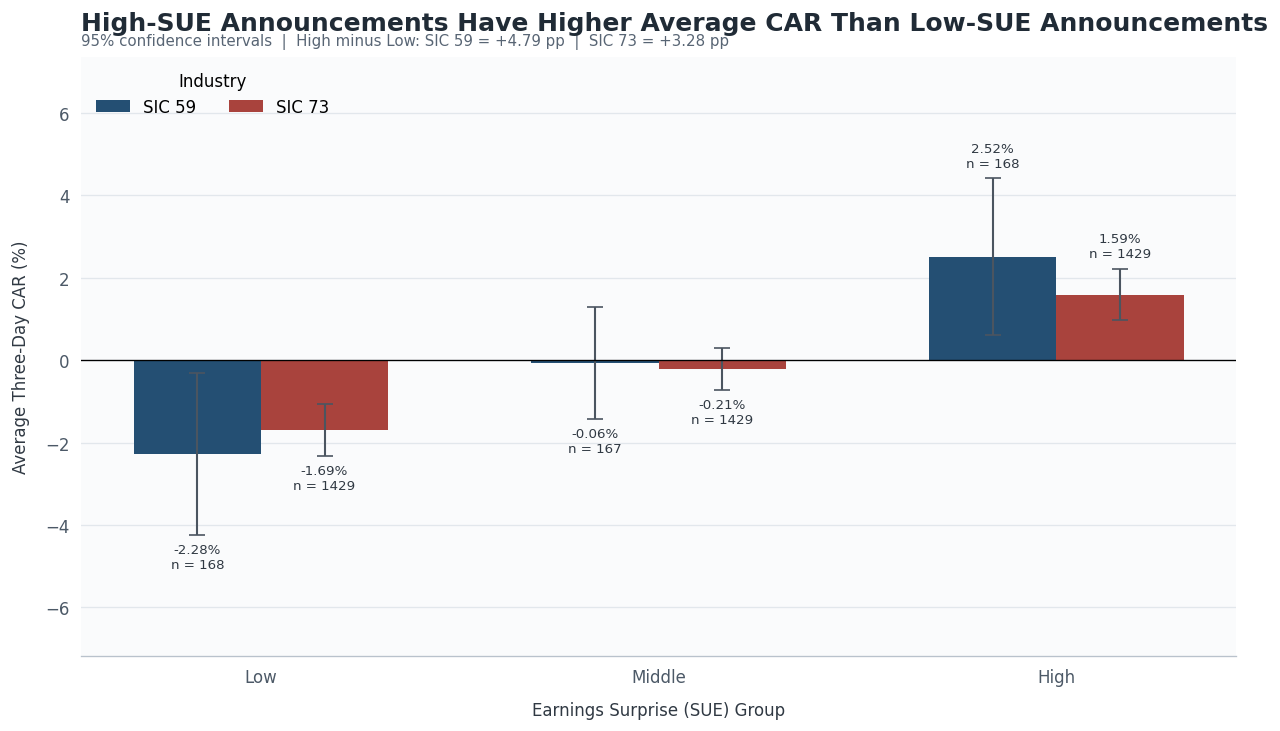

In [54]:
# ===== Part 2. Three SUE groups and Figure 1 =====
# SUE groups were created earlier in the notebook for both industries.

LABELS = ["Low", "Middle", "High"]
INDUSTRY_COLORS = {"SIC 59": "#244F73", "SIC 73": "#A9433D"}

# Primary industry: SIC 59
primary_table = events.groupby(
    "SUE_group", observed=False
)["CAR"].agg(n="count", mean="mean", sd="std")
primary_table["se"] = primary_table["sd"] / np.sqrt(primary_table["n"])
primary_table["ci95"] = 1.96 * primary_table["se"]
primary_table["industry"] = "SIC 59"

# Peer industry: SIC 73
partner_table = partner_events.groupby(
    "SUE_group", observed=False
)["CAR"].agg(n="count", mean="mean", sd="std")
partner_table["se"] = partner_table["sd"] / np.sqrt(partner_table["n"])
partner_table["ci95"] = 1.96 * partner_table["se"]
partner_table["industry"] = "SIC 73"

figure1_table = pd.concat(
    [primary_table, partner_table]
).reset_index()

figure1_table["mean_pct"] = figure1_table["mean"] * 100
figure1_table["ci95_pct"] = figure1_table["ci95"] * 100

display(
    figure1_table[
        ["industry", "SUE_group", "n", "mean_pct", "ci95_pct"]
    ].round(2)
)

# Figure 1: average three-day CAR by SUE group, comparing both industries.
fig, ax = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
fig.patch.set_facecolor("white")
ax.set_facecolor("#FAFBFC")

x = np.arange(len(LABELS))
width = 0.32

for offset, industry in [
    (-width / 2, "SIC 59"),
    (width / 2, "SIC 73")
]:
    t = (
        figure1_table[figure1_table["industry"] == industry]
        .set_index("SUE_group")
        .reindex(LABELS)
    )

    ax.bar(
        x + offset,
        t["mean_pct"],
        width,
        yerr=t["ci95_pct"],
        capsize=5,
        color=INDUSTRY_COLORS[industry],
        label=industry,
        error_kw={"elinewidth": 1.25, "ecolor": "#4B5560"}
    )

    for i, group in enumerate(LABELS):
        mean_value = t.loc[group, "mean_pct"]
        ci_value = t.loc[group, "ci95_pct"]
        n_value = t.loc[group, "n"]
        top = mean_value + ci_value if mean_value >= 0 else mean_value - ci_value

        ax.annotate(
            f"{mean_value:.2f}%\nn = {int(n_value)}",
            (x[i] + offset, top),
            xytext=(0, 5 if mean_value >= 0 else -5),
            textcoords="offset points",
            ha="center",
            va="bottom" if mean_value >= 0 else "top",
            fontsize=8, color="#303943", fontweight="medium"
        )

# Build the title from the actual High-minus-Low group averages.
gap_59 = (
    primary_table.loc["High", "mean"] -
    primary_table.loc["Low", "mean"]
) * 100
gap_73 = (
    partner_table.loc["High", "mean"] -
    partner_table.loc["Low", "mean"]
) * 100

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(LABELS)
ax.set_title(
    "High-SUE Announcements Have Higher Average CAR Than Low-SUE Announcements",
    loc="left", fontsize=15, fontweight="bold", color="#202B36", pad=16
)
ax.text(0, 1.02, f"95% confidence intervals  |  High minus Low: SIC 59 = {gap_59:+.2f} pp  |  SIC 73 = {gap_73:+.2f} pp", transform=ax.transAxes, fontsize=9, color="#586574")
ax.set_xlabel("Earnings Surprise (SUE) Group", fontsize=10, labelpad=9, color="#303943")
ax.set_ylabel("Average Three-Day CAR (%)", fontsize=10, labelpad=9, color="#303943")
ax.legend(title="Industry", frameon=False, ncol=2, loc="upper left")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#B9C2CC")
ax.tick_params(axis="both", colors="#4C5967", length=0, pad=7)
ax.grid(axis="y", color="#DCE2E8", linewidth=0.8, alpha=0.8)
ax.set_axisbelow(True)
ax.margins(y=0.34)

plt.tight_layout()
fig.savefig("figure1_groups.png", dpi=200)
plt.show()


In [55]:
# ===== Part 3. Welch t-test: High vs Low SUE =====

# Primary industry: SIC 59
high = events.loc[events["SUE_group"] == "High", "CAR"]
low = events.loc[events["SUE_group"] == "Low", "CAR"]

t_primary, p_primary = stats.ttest_ind(high, low, equal_var=False)
gap_primary = (high.mean() - low.mean()) * 100

print(
    f"SIC 59: High - Low = {gap_primary:.2f} percentage points "
    f"| t = {t_primary:.2f} | p = {format_p_value(p_primary)}"
)


# Partner industry: SIC 73
high_partner = partner_events.loc[
    partner_events["SUE_group"] == "High", "CAR"
]
low_partner = partner_events.loc[
    partner_events["SUE_group"] == "Low", "CAR"
]

t_partner, p_partner = stats.ttest_ind(
    high_partner, low_partner, equal_var=False
)
gap_partner = (high_partner.mean() - low_partner.mean()) * 100

print(
    f"SIC 73: High - Low = {gap_partner:.2f} percentage points "
    f"| t = {t_partner:.2f} | p = {format_p_value(p_partner)}"
)


SIC 59: High - Low = 4.79 percentage points | t = 3.43 | p = <0.001
SIC 73: High - Low = 3.28 percentage points | t = 7.25 | p = <0.001


## Figure 2. SUE and three-day CAR

This scatter plot compares the relationship between earnings surprises and three day cumulative abnormal returns in SIC 59 and SIC 73. Each industry has its own fitted regression line.

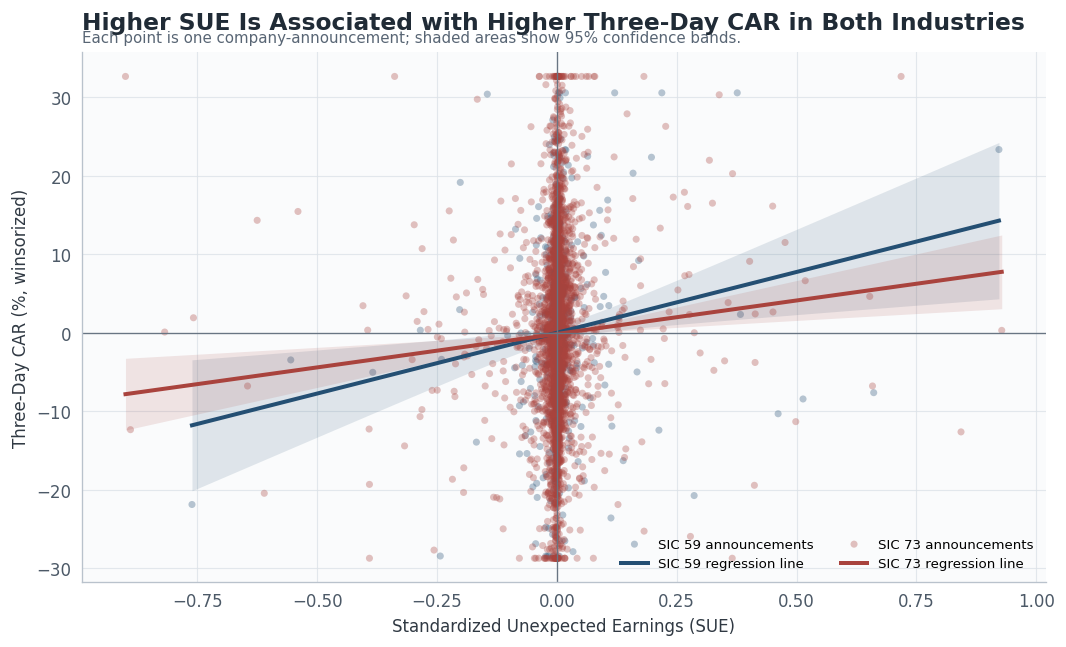

In [56]:
# Create the same 1st/99th percentile winsorized CAR variables used in Part 4.
# This is needed here because Figure 2 appears before the Part 4 regression section.
lo_59_fig2, hi_59_fig2 = events["CAR"].quantile([0.01, 0.99])
events["CAR_w"] = events["CAR"].clip(lo_59_fig2, hi_59_fig2)

lo_73_fig2, hi_73_fig2 = partner_events["CAR"].quantile([0.01, 0.99])
partner_events["CAR_w"] = partner_events["CAR"].clip(lo_73_fig2, hi_73_fig2)

# ===== Figure 2. Baseline scatter plot and regression lines =====
# This follows the in-class example: plot every observation, fit the baseline
# CAR = a + b*SUE regression, and show the 95% confidence band.
# The project version overlays both industries for comparison.

fig, ax = plt.subplots(figsize=(9, 5.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("#FAFBFC")

for industry, data, color in [
    ("SIC 59", events, INDUSTRY_COLORS["SIC 59"]),
    ("SIC 73", partner_events, INDUSTRY_COLORS["SIC 73"])
]:
    # Baseline regression for this industry (winsorized CAR, as in class example)
    model = smf.ols("CAR_w ~ SUE", data=data).fit()

    # Every company-announcement observation
    ax.scatter(
        data["SUE"], data["CAR_w"] * 100,
        s=18, alpha=0.32, color=color, edgecolors="none",
        label=f"{industry} announcements"
    )

    # Regression line and its 95% confidence band
    grid = pd.DataFrame({
        "SUE": np.linspace(data["SUE"].min(), data["SUE"].max(), 100)
    })
    pred = model.get_prediction(grid).summary_frame(alpha=0.05)

    ax.fill_between(
        grid["SUE"],
        pred["mean_ci_lower"] * 100,
        pred["mean_ci_upper"] * 100,
        color=color, alpha=0.13, linewidth=0
    )
    ax.plot(
        grid["SUE"], pred["mean"] * 100,
        color=color, linewidth=2.4,
        label=f"{industry} regression line"
    )

ax.axhline(0, color="#687583", linewidth=0.8)
ax.axvline(0, color="#687583", linewidth=0.8)
ax.set_title(
    "Higher SUE Is Associated with Higher Three-Day CAR in Both Industries",
    loc="left", fontsize=14, fontweight="bold", color="#202B36", pad=14
)
ax.text(
    0, 1.02,
    "Each point is one company-announcement; shaded areas show 95% confidence bands.",
    transform=ax.transAxes, fontsize=9, color="#586574"
)
ax.set_xlabel("Standardized Unexpected Earnings (SUE)")
ax.set_ylabel("Three-Day CAR (%, winsorized)")
ax.legend(frameon=False, ncol=2, fontsize=8, loc="best")
ax.spines[["top", "right"]].set_visible(False)
ax.spines["left"].set_color("#B9C2CC")
ax.spines["bottom"].set_color("#B9C2CC")
ax.tick_params(axis="both", colors="#4C5967", length=0, pad=6)
ax.grid(axis="both", color="#DCE2E8", linewidth=0.7, alpha=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig("figure2_baseline_regression.png", dpi=220, bbox_inches="tight")
plt.show()


## Figure 3. Share of loss-making announcements by SUE group

This figure checks one possible reason the industries may differ: whether the share of announcements with negative quarterly EPS varies across the Low, Middle, and High SUE groups, and whether that pattern differs between SIC 59 and SIC 73. It uses the current quarter EPS already in both event datasets. A loss is defined as EPS below zero, matching the loss indicator used in the interaction regressions.

,Industry,SUE_group,announcements,loss_share_pct
0,SIC 59,Low,168,45.83
3,SIC 73,Low,1429,54.79
1,SIC 59,Middle,167,14.97
4,SIC 73,Middle,1429,21.62
2,SIC 59,High,168,25.0
5,SIC 73,High,1429,24.84


/tmp/40761249.1.jupyterhub.q/ipykernel_1771099/3693938839.py:95: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


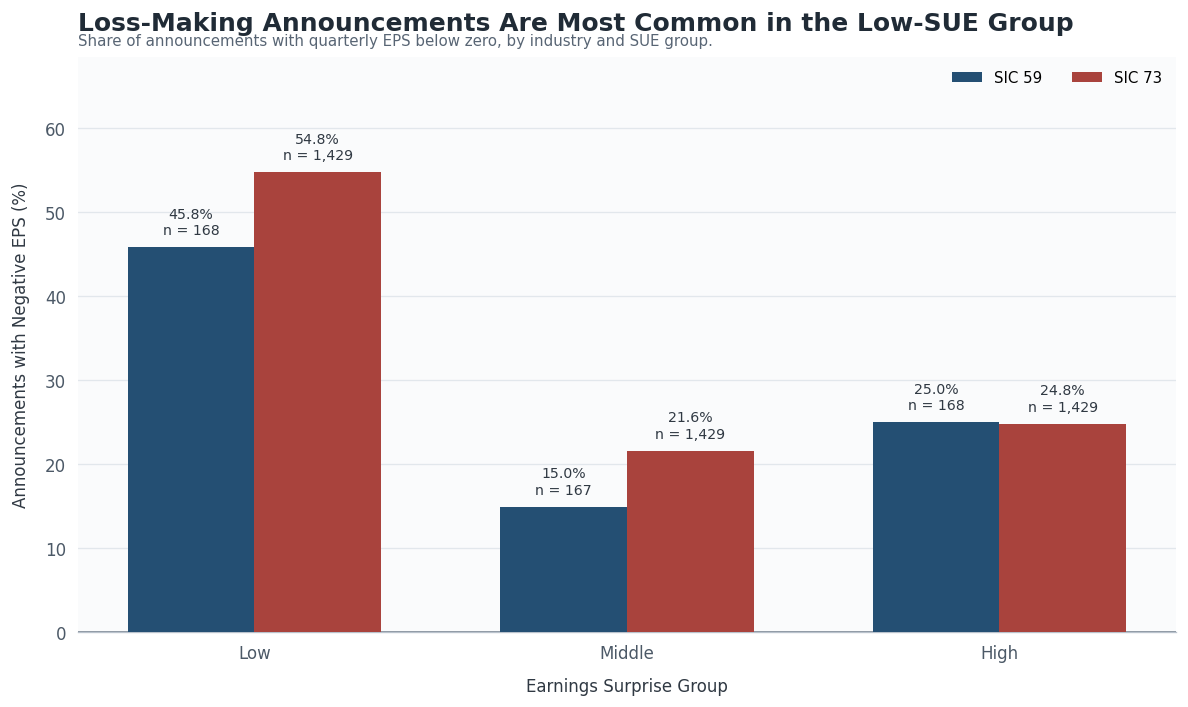

In [57]:
# ===== Figure 3. Share of loss-making announcements by SUE group =====

loss_share_59 = (
    events.assign(loss=events["epspxq"].lt(0))
    .groupby("SUE_group", observed=False)["loss"]
    .agg(loss_share="mean", announcements="count")
    .reset_index()
)
loss_share_59["Industry"] = "SIC 59"

loss_share_73 = (
    partner_events.assign(loss=partner_events["epspxq"].lt(0))
    .groupby("SUE_group", observed=False)["loss"]
    .agg(loss_share="mean", announcements="count")
    .reset_index()
)
loss_share_73["Industry"] = "SIC 73"

loss_share = pd.concat(
    [loss_share_59, loss_share_73], ignore_index=True
)
loss_share["loss_share_pct"] = loss_share["loss_share"] * 100

# Keep the group order consistent with Figure 1.
loss_share["SUE_group"] = pd.Categorical(
    loss_share["SUE_group"], categories=LABELS, ordered=True
)
loss_share = loss_share.sort_values(["SUE_group", "Industry"])

display(
    loss_share[
        ["Industry", "SUE_group", "announcements", "loss_share_pct"]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
fig.patch.set_facecolor("white")
ax.set_facecolor("#FAFBFC")

x = np.arange(len(LABELS))
width = 0.34
for offset, industry in [
    (-width / 2, "SIC 59"),
    (width / 2, "SIC 73")
]:
    t = (
        loss_share[loss_share["Industry"] == industry]
        .set_index("SUE_group")
        .reindex(LABELS)
    )
    bars = ax.bar(
        x + offset,
        t["loss_share_pct"],
        width,
        color=INDUSTRY_COLORS[industry],
        label=industry,
        zorder=3
    )
    for bar, value, n in zip(
        bars, t["loss_share_pct"], t["announcements"]
    ):
        ax.annotate(
            f"{value:.1f}%\nn = {int(n):,}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8.5,
            color="#303943",
            fontweight="medium"
        )

ax.axhline(0, color="#687583", linewidth=0.9, zorder=2)
ax.set_xticks(x)
ax.set_xticklabels(LABELS)
ax.set_title(
    "Loss-Making Announcements Are Most Common in the Low-SUE Group",
    loc="left", fontsize=15, fontweight="bold", color="#202B36", pad=16
)
ax.text(
    0, 1.02,
    "Share of announcements with quarterly EPS below zero, by industry and SUE group.",
    transform=ax.transAxes, fontsize=9, color="#586574"
)
ax.set_xlabel("Earnings Surprise Group", fontsize=10, labelpad=9, color="#303943")
ax.set_ylabel("Announcements with Negative EPS (%)", fontsize=10, labelpad=9, color="#303943")
ax.legend(frameon=False, ncol=2, fontsize=9, loc="upper right")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#B9C2CC")
ax.tick_params(axis="both", colors="#4C5967", length=0, pad=7)
ax.grid(axis="y", color="#DCE2E8", linewidth=0.8, alpha=0.8, zorder=0)
ax.set_axisbelow(True)
ax.set_ylim(0, max(5, loss_share["loss_share_pct"].max() * 1.25))
plt.tight_layout()
fig.savefig("figure3_loss_share_by_sue_group.png", dpi=220, bbox_inches="tight")
plt.show()


## Optional Figure 4. Event study: cumulative abnormal returns from Day −5 to Day +5

Shows how abnormal returns develop around earnings announcements. It uses the existing daily abnormal return data for each industry and groups announcements by Low, Middle, and High SUE. For each event day, it calculates the average abnormal return and then adds those averages over time to form cumulative average abnormal returns

,Industry,SUE_group,offset,announcements,mean_ar,CAAR
0,SIC 59,Low,-5,168,-0.0008,-0.0008
1,SIC 59,Low,-4,168,-0.0037,-0.0045
2,SIC 59,Low,-3,168,0.0012,-0.0033
3,SIC 59,Low,-2,168,0.0016,-0.0018
4,SIC 59,Low,-1,168,0.0018,0.0001
...,...,...,...,...,...,...
61,SIC 73,High,1,1429,0.0094,0.0165
62,SIC 73,High,2,1428,0.0005,0.017
63,SIC 73,High,3,1428,0.0,0.017
64,SIC 73,High,4,1428,0.0004,0.0174


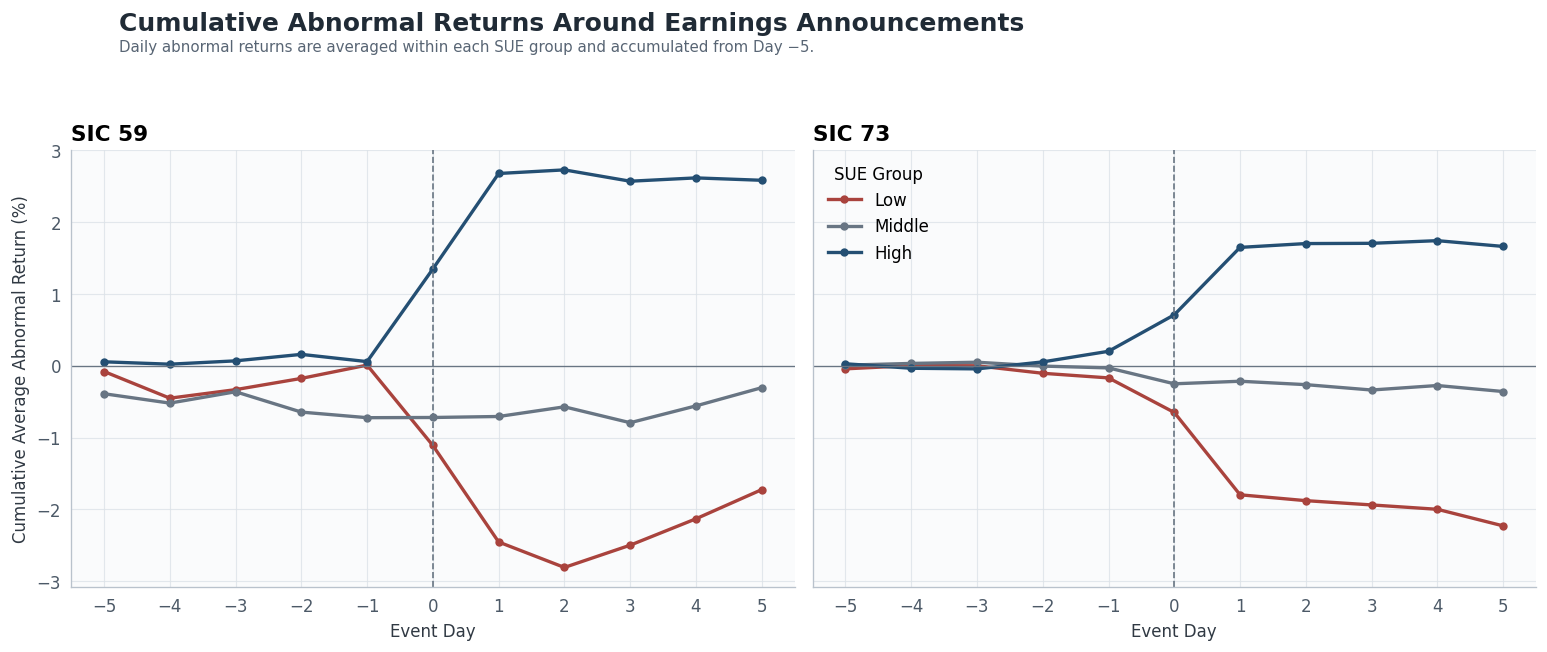

In [58]:
# ===== Optional Figure 4. Event study: cumulative abnormal returns, Day -5 to Day +5 =====

# Create the event-day offsets.
event_offsets = pd.DataFrame({"offset": range(-5, 6)})

# SIC 59: match each announcement to daily abnormal returns from Day -5 to Day +5.
event_study_59 = events[
    ["event_id", "permno", "day0", "SUE_group"]
].merge(event_offsets, how="cross")

event_study_59["tday"] = (
    event_study_59["day0"] + event_study_59["offset"]
)

event_study_59 = event_study_59.merge(
    daily[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

event_study_59["Industry"] = "SIC 59"

# SIC 73: repeat the same event-window matching.
event_study_73 = partner_events[
    ["event_id", "permno", "day0", "SUE_group"]
].merge(event_offsets, how="cross")

event_study_73["tday"] = (
    event_study_73["day0"] + event_study_73["offset"]
)

event_study_73 = event_study_73.merge(
    partner_daily[["permno", "tday", "ar"]],
    on=["permno", "tday"],
    how="left",
    validate="many_to_one"
)

event_study_73["Industry"] = "SIC 73"

# Combine the industries and calculate average abnormal returns by event day.
event_study = pd.concat(
    [event_study_59, event_study_73],
    ignore_index=True
)

event_study_average = (
    event_study
    .groupby(["Industry", "SUE_group", "offset"], observed=False)["ar"]
    .agg(mean_ar="mean", announcements="count")
    .reset_index()
    .sort_values(["Industry", "SUE_group", "offset"])
)

# Cumulative average abnormal return (CAAR) from Day -5 through each event day.
event_study_average["CAAR"] = (
    event_study_average
    .groupby(["Industry", "SUE_group"], observed=False)["mean_ar"]
    .cumsum()
)

display(
    event_study_average[
        ["Industry", "SUE_group", "offset", "announcements", "mean_ar", "CAAR"]
    ].round(4)
)

# Plot one panel per industry, with a separate line for each SUE group.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
fig.patch.set_facecolor("white")

group_colors = {
    "Low": "#A9433D",
    "Middle": "#687583",
    "High": "#244F73"
}

for ax, industry in zip(axes, ["SIC 59", "SIC 73"]):
    ax.set_facecolor("#FAFBFC")
    industry_data = event_study_average[
        event_study_average["Industry"] == industry
    ]

    for group in LABELS:
        line_data = (
            industry_data[industry_data["SUE_group"] == group]
            .sort_values("offset")
        )

        ax.plot(
            line_data["offset"],
            line_data["CAAR"] * 100,
            marker="o",
            markersize=4,
            linewidth=2,
            color=group_colors[group],
            label=group
        )

    ax.axvline(0, color="#687583", linestyle="--", linewidth=1)
    ax.axhline(0, color="#687583", linewidth=0.8)
    ax.set_title(industry, loc="left", fontsize=13, fontweight="bold")
    ax.set_xlabel("Event Day")
    ax.set_xticks(range(-5, 6))
    ax.grid(axis="both", color="#DCE2E8", linewidth=0.7, alpha=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines["left"].set_color("#B9C2CC")
    ax.spines["bottom"].set_color("#B9C2CC")
    ax.tick_params(axis="both", colors="#4C5967", length=0, pad=6)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Cumulative Average Abnormal Return (%)")
axes[1].legend(title="SUE Group", frameon=False)
fig.suptitle(
    "Cumulative Abnormal Returns Around Earnings Announcements",
    x=0.08, ha="left", fontsize=15, fontweight="bold", color="#202B36"
)
fig.text(
    0.08, 0.92,
    "Daily abnormal returns are averaged within each SUE group and accumulated from Day −5.",
    fontsize=9, color="#586574"
)
plt.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(
    "figure4_event_study_day_minus5_to_plus5.png",
    dpi=220,
    bbox_inches="tight"
)
plt.show()


In [59]:
# ===== Part 4a. Examine CAR extremes and winsorize at 1% and 99% =====

# SIC 59
print("SIC 59 — original SUE and CAR:")
display(events[["SUE", "CAR"]].describe().round(3))

lo_59, hi_59 = events["CAR"].quantile([0.01, 0.99])
events["CAR_w"] = events["CAR"].clip(lo_59, hi_59)

print(
    "SIC 59 — CAR winsorization cutoffs:",
    round(lo_59, 6), "to", round(hi_59, 6)
)
print(
    "SIC 59 — rows changed:",
    int((events["CAR"] != events["CAR_w"]).sum()),
    "of", len(events)
)

# SIC 73
print("\nSIC 73 — original SUE and CAR:")
display(partner_events[["SUE", "CAR"]].describe().round(3))

lo_73, hi_73 = partner_events["CAR"].quantile([0.01, 0.99])
partner_events["CAR_w"] = partner_events["CAR"].clip(lo_73, hi_73)

print(
    "SIC 73 — CAR winsorization cutoffs:",
    round(lo_73, 6), "to", round(hi_73, 6)
)
print(
    "SIC 73 — rows changed:",
    int((partner_events["CAR"] != partner_events["CAR_w"]).sum()),
    "of", len(partner_events)
)


# ===== Part 4b. CAR = a + b x SUE: original and winsorized =====

# SIC 59
model_59 = smf.ols("CAR ~ SUE", data=events).fit()
model_59_w = smf.ols("CAR_w ~ SUE", data=events).fit()

# SIC 73
model_73 = smf.ols("CAR ~ SUE", data=partner_events).fit()
model_73_w = smf.ols("CAR_w ~ SUE", data=partner_events).fit()

regression_results = pd.DataFrame({
    "b (SUE slope)": [
        model_59.params["SUE"], model_59_w.params["SUE"],
        model_73.params["SUE"], model_73_w.params["SUE"]
    ],
    "CAR change for +0.01 SUE (pp)": [
        model_59.params["SUE"] * 0.01 * 100,
        model_59_w.params["SUE"] * 0.01 * 100,
        model_73.params["SUE"] * 0.01 * 100,
        model_73_w.params["SUE"] * 0.01 * 100
    ],
    "p-value of b": [
        model_59.pvalues["SUE"], model_59_w.pvalues["SUE"],
        model_73.pvalues["SUE"], model_73_w.pvalues["SUE"]
    ],
    "R-squared": [
        model_59.rsquared, model_59_w.rsquared,
        model_73.rsquared, model_73_w.rsquared
    ],
    "n": [
        int(model_59.nobs), int(model_59_w.nobs),
        int(model_73.nobs), int(model_73_w.nobs)
    ]
}, index=[
    "SIC 59 — original CAR",
    "SIC 59 — winsorized CAR",
    "SIC 73 — original CAR",
    "SIC 73 — winsorized CAR"
]).round(4)

display(regression_results)

print("SIC 59 — original CAR regression:")
print(model_59.summary())
print("SIC 59 — winsorized CAR regression:")
print(model_59_w.summary())

print("SIC 73 — original CAR regression:")
print(model_73.summary())
print("SIC 73 — winsorized CAR regression:")
print(model_73_w.summary())


SIC 59 — original SUE and CAR:


,SUE,CAR
count,503.0,503.0
mean,0.005,0.001
std,0.091,0.118
min,-0.761,-0.5
25%,-0.007,-0.069
50%,0.001,0.001
75%,0.008,0.063
max,0.922,0.546


SIC 59 — CAR winsorization cutoffs: -0.284349 to 0.305779
SIC 59 — rows changed: 12 of 503

SIC 73 — original SUE and CAR:


,SUE,CAR
count,4287.0,4287.0
mean,0.001,-0.001
std,0.062,0.114
min,-0.9,-0.761
25%,-0.003,-0.061
50%,0.001,-0.002
75%,0.005,0.055
max,0.928,0.96


SIC 73 — CAR winsorization cutoffs: -0.287182 to 0.326687
SIC 73 — rows changed: 86 of 4287


,b (SUE slope),CAR change for +0.01 SUE (pp),p-value of b,R-squared,n
SIC 59 — original CAR,0.1844,0.1844,0.0015,0.0200,503
SIC 59 — winsorized CAR,0.1549,0.1549,0.0051,0.0156,503
SIC 73 — original CAR,0.1163,0.1163,0.0000,0.0040,4287
SIC 73 — winsorized CAR,0.0853,0.0853,0.0010,0.0025,4287


SIC 59 — original CAR regression:
                            OLS Regression Results                            
Dep. Variable:                    CAR   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     10.25
Date:                Mon, 23 Nov 2026   Prob (F-statistic):            0.00146
Time:                        16:14:14   Log-Likelihood:                 366.88
No. Observations:                 503   AIC:                            -729.8
Df Residuals:                     501   BIC:                            -721.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0

## Optional regressions: year fixed effects and loss interaction

These optional models check whether the relationship between SUE and winsorized CAR changes after accounting for fiscal-year differences and whether the company reports a loss. A loss equals 1 when current-quarter EPS (`epspxq`) is negative. Standard errors are clustered by company (`gvkey`).

In [60]:
# ===== Optional Part 4c. Year fixed effects and loss interaction =====
# Loss = 1 when current-quarter EPS is negative.
# Standard errors are clustered by company (gvkey).

from statsmodels.iolib.summary2 import summary_col

events["fyearq"] = pd.to_numeric(
    events["fyearq"], errors="coerce"
).astype("float64")
events["loss"] = (events["epspxq"] < 0).astype(int)

partner_events["fyearq"] = pd.to_numeric(
    partner_events["fyearq"], errors="coerce"
).astype("float64")
partner_events["loss"] = (partner_events["epspxq"] < 0).astype(int)

cl_59 = dict(
    cov_type="cluster",
    cov_kwds={"groups": events["gvkey"]}
)
cl_73 = dict(
    cov_type="cluster",
    cov_kwds={"groups": partner_events["gvkey"]}
)

# SIC 59 models.
m59_1 = smf.ols("CAR_w ~ SUE", data=events).fit(**cl_59)
m59_2 = smf.ols(
    "CAR_w ~ SUE + C(fyearq)", data=events
).fit(**cl_59)
m59_3 = smf.ols(
    "CAR_w ~ SUE * loss + C(fyearq)", data=events
).fit(**cl_59)

# SIC 73 models.
m73_1 = smf.ols(
    "CAR_w ~ SUE", data=partner_events
).fit(**cl_73)
m73_2 = smf.ols(
    "CAR_w ~ SUE + C(fyearq)", data=partner_events
).fit(**cl_73)
m73_3 = smf.ols(
    "CAR_w ~ SUE * loss + C(fyearq)", data=partner_events
).fit(**cl_73)

print("SIC 59 — clustered regressions:")
sic59_regression_table = summary_col(
    [m59_1, m59_2, m59_3],
    stars=True,
    model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
    regressor_order=["SUE", "loss", "SUE:loss"],
    drop_omitted=True,
    info_dict={
        "R2": lambda m: f"{m.rsquared:.3f}",
        "n": lambda m: f"{int(m.nobs)}"
    }
)
print(sic59_regression_table)

print("SIC 73 — clustered regressions:")
sic73_regression_table = summary_col(
    [m73_1, m73_2, m73_3],
    stars=True,
    model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
    regressor_order=["SUE", "loss", "SUE:loss"],
    drop_omitted=True,
    info_dict={
        "R2": lambda m: f"{m.rsquared:.3f}",
        "n": lambda m: f"{int(m.nobs)}"
    }
)
print(sic73_regression_table)


SIC 59 — clustered regressions:

               (1) base (2) year FE (3) year FE + loss
------------------------------------------------------
SUE            0.1549** 0.1668**    0.2484            
               (0.0699) (0.0682)    (0.2190)          
loss                                -0.0207*          
                                    (0.0112)          
SUE:loss                            -0.1092           
                                    (0.2509)          
R-squared      0.0156   0.0302      0.0387            
R-squared Adj. 0.0136   0.0185      0.0231            
R2             0.016    0.030       0.039             
n              503      503         503               
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
SIC 73 — clustered regressions:

               (1) base (2) year FE (3) year FE + loss
------------------------------------------------------
SUE            0.0853** 0.0881**    0.2117***         
               (0.0411) (0.0413)    (0.0749)      

## 6. Final comparison: SIC 59 and SIC 73

This section puts the two industries side by side. Table reports the counts after each merge and Rules 1–6. The comparison table reports the final sample sizes, High-minus-Low Welch tests, and the original and winsorized SUE regressions.


In [61]:
# ===== Part 5a. Combined sample-construction table (Rules 1–6) =====

sample_table_59 = sample_table.copy()
sample_table_59.insert(0, "Industry", "SIC 59")

sample_table_73 = partner_sample_table.copy()
sample_table_73.insert(0, "Industry", "SIC 73")

combined_sample_table = pd.concat(
    [sample_table_59, sample_table_73],
    ignore_index=True
)

display(combined_sample_table)


# ===== Part 5b. One comparison table for both industries =====

comparison_table = pd.DataFrame([
    {
        "Industry": "SIC 59",
        "SIC": "59",
        "Announcements": len(events),
        "Companies": events["gvkey"].nunique(),
        "High - Low CAR (pp)": gap_primary,
        "Welch t-stat": t_primary,
        "Welch p-value": p_primary,
        "SUE slope (original)": model_59.params["SUE"],
        "Slope p-value (original)": model_59.pvalues["SUE"],
        "R-squared (original)": model_59.rsquared,
        "SUE slope (winsorized)": model_59_w.params["SUE"],
        "Slope p-value (winsorized)": model_59_w.pvalues["SUE"],
        "R-squared (winsorized)": model_59_w.rsquared
    },
    {
        "Industry": "SIC 73",
        "SIC": "73",
        "Announcements": len(partner_events),
        "Companies": partner_events["gvkey"].nunique(),
        "High - Low CAR (pp)": gap_partner,
        "Welch t-stat": t_partner,
        "Welch p-value": p_partner,
        "SUE slope (original)": model_73.params["SUE"],
        "Slope p-value (original)": model_73.pvalues["SUE"],
        "R-squared (original)": model_73.rsquared,
        "SUE slope (winsorized)": model_73_w.params["SUE"],
        "Slope p-value (winsorized)": model_73_w.pvalues["SUE"],
        "R-squared (winsorized)": model_73_w.rsquared
    }
]).set_index("Industry")

comparison_table["Welch p-value"] = comparison_table["Welch p-value"].map(format_p_value)
comparison_table["Slope p-value (original)"] = comparison_table["Slope p-value (original)"].map(format_p_value)
comparison_table["Slope p-value (winsorized)"] = comparison_table["Slope p-value (winsorized)"].map(format_p_value)

display(comparison_table.round(4))


# ===== Part 5c. Plain-English interpretation for the client =====

def describe_ttest(industry, gap, t_stat, p_value):
    direction = "more" if gap >= 0 else "less"
    sentence1 = (
        f"{industry}: High-SUE firms earned on average "
        f"{abs(gap):.2f} percentage points {direction} CAR than Low-SUE firms."
    )
    if p_value < 0.05:
        sentence2 = (
            f"The difference is statistically significant "
            f"(Welch t = {t_stat:.2f}, p = {format_p_value(p_value)}), "
            "so the data provide evidence of a difference."
        )
    else:
        sentence2 = (
            f"The difference is not statistically significant "
            f"(Welch t = {t_stat:.2f}, p = {format_p_value(p_value)}), "
            "so we cannot rule out chance as an explanation."
        )
    print(sentence1)
    print(sentence2)
    print()


def describe_regression(industry, model, model_w):
    b = model.params["SUE"]
    effect_pp = b * 0.01 * 100
    direction = "increase" if effect_pp >= 0 else "decrease"

    print(
        f"{industry}: A 0.01 increase in SUE is associated with a "
        f"{abs(effect_pp):.3f} percentage-point {direction} in three-day CAR."
    )
    print(
        f"The SUE coefficient p-value is {format_p_value(model.pvalues['SUE'])}; "
        f"R-squared is {model.rsquared:.4f}; n = {int(model.nobs)}."
    )
    print(
        f"After winsorizing CAR at 1%/99%, the slope is "
        f"{model_w.params['SUE']:.4f} (p = {format_p_value(model_w.pvalues['SUE'])}), "
        f"with R-squared = {model_w.rsquared:.4f}."
    )
    print()


describe_ttest("SIC 59", gap_primary, t_primary, p_primary)
describe_ttest("SIC 73", gap_partner, t_partner, p_partner)

describe_regression("SIC 59", model_59, model_59_w)
describe_regression("SIC 73", model_73, model_73_w)


# ===== Part 5e. Outlier sensitivity summary =====

outlier_sensitivity = pd.DataFrame([
    {
        "Industry": "SIC 59",
        "1st percentile CAR": lo_59,
        "99th percentile CAR": hi_59,
        "Rows winsorized": int((events["CAR"] != events["CAR_w"]).sum()),
        "Original SUE slope": model_59.params["SUE"],
        "Winsorized SUE slope": model_59_w.params["SUE"]
    },
    {
        "Industry": "SIC 73",
        "1st percentile CAR": lo_73,
        "99th percentile CAR": hi_73,
        "Rows winsorized": int(
            (partner_events["CAR"] != partner_events["CAR_w"]).sum()
        ),
        "Original SUE slope": model_73.params["SUE"],
        "Winsorized SUE slope": model_73_w.params["SUE"]
    }
]).set_index("Industry")

display(outlier_sensitivity.round(4))


,Industry,Step,Rows before,Rows after,Companies left,Why did it change?
0,SIC 59,"Compustat quarterly data, SIC 59",1110,1110,53,Quarterly company data pulled from Compustat.
1,SIC 59,Merge 1: valid company-stock link,1110,1029,53,Matched gvkey to the permno link active on rdq...
2,SIC 59,Merge 2: earlier-quarter EPS and price,1029,1029,53,Added EPS four quarters ago and price one quar...
3,SIC 59,Rule 1: announcement date is known,1029,1015,53,Removed observations without an announcement d...
4,SIC 59,Rule 2: announcement date range,1015,690,50,Removed announcements outside the requested da...
5,SIC 59,Rule 3: SUE can be calculated,690,638,50,Removed observations missing an input needed f...
6,SIC 59,Rule 4: previous-quarter price is at least $5,638,504,45,Removed observations with previous-quarter pri...
7,SIC 59,Rule 5: absolute SUE is no greater than 1,504,504,45,Removed observations where absolute SUE is gre...
8,SIC 59,Merge 3: daily stock return and market return,40467,40467,45,Matched each stock-day to the market return fo...
9,SIC 59,"Merge 4: add abnormal returns for days -1, 0, +1",1512,1512,45,Matched each event-window day to the same stoc...


,SIC,Announcements,Companies,High - Low CAR (pp),Welch t-stat,Welch p-value,SUE slope (original),Slope p-value (original),R-squared (original),SUE slope (winsorized),Slope p-value (winsorized),R-squared (winsorized)
Industry,,,,,,,,,,,,
SIC 59,59,503,45,4.7923,3.4329,<0.001,0.1844,0.001,0.020,0.1549,0.005,0.0156
SIC 73,73,4287,387,3.2835,7.2508,<0.001,0.1163,<0.001,0.004,0.0853,<0.001,0.0025


SIC 59: High-SUE firms earned on average 4.79 percentage points more CAR than Low-SUE firms.
The difference is statistically significant (Welch t = 3.43, p = <0.001), so the data provide evidence of a difference.

SIC 73: High-SUE firms earned on average 3.28 percentage points more CAR than Low-SUE firms.
The difference is statistically significant (Welch t = 7.25, p = <0.001), so the data provide evidence of a difference.

SIC 59: A 0.01 increase in SUE is associated with a 0.184 percentage-point increase in three-day CAR.
The SUE coefficient p-value is 0.001; R-squared is 0.0200; n = 503.
After winsorizing CAR at 1%/99%, the slope is 0.1549 (p = 0.005), with R-squared = 0.0156.

SIC 73: A 0.01 increase in SUE is associated with a 0.116 percentage-point increase in three-day CAR.
The SUE coefficient p-value is <0.001; R-squared is 0.0040; n = 4287.
After winsorizing CAR at 1%/99%, the slope is 0.0853 (p = <0.001), with R-squared = 0.0025.



,1st percentile CAR,99th percentile CAR,Rows winsorized,Original SUE slope,Winsorized SUE slope
Industry,,,,,
SIC 59,-0.2843,0.3058,12,0.1844,0.1549
SIC 73,-0.2872,0.3267,86,0.1163,0.0853
